# 01 · Monte Carlo cost engine

This notebook builds the paper's Monte Carlo ensemble of nuclear cost trajectories. For each of
six US deployment schedules (the paper calls them *target trajectories*: 117 GW to 400 GW of US
nuclear capacity in 2050), it draws 10,000 joint samples of the uncertain inputs and turns each
sample into a 2024–2050 path of overnight capital cost, construction duration and financed
capital cost for two reactor classes. Every later notebook that needs a cost sample reads the
per-draw file this notebook writes. Every cost number here is conditional on its schedule being
built: the notebook states "if the United States builds X, costs consistent with X look like Y",
and it never predicts how much nuclear the United States will build.

**Inputs** (all in the ReEDS fork; none is produced by another notebook)
- `inputs/nuclear_learning/US_SCHEDULES.csv` and `nuclear_cap_trajectory_{scen}.csv`: the six
  schedules and the ReEDS mandate files (read and compared, never written).
- `inputs/nuclear_learning/rds2_2025_units.csv` through `nlpaper.pris_loader`: the IAEA PRIS
  unit list (reactor history, pipeline, construction durations).
- `inputs/financials/{financials_sys_ATB2024, inflation_default, financials_tech_ATB2024,
  depreciation_schedules_default, construction_schedules_default, construction_schedules_mc}.csv`:
  the ReEDS financing inputs.
- `inputs/financials/deflator.csv` through `plotstyle.to2025`: the dollar-year conversion for display.

**Outputs** (`z-ethan/results/exports/01/` unless stated)
- `mc_perdraw.npz`: every draw's parameters, program-cost scores, winners and the four full-channel
  trajectory arrays (git-ignored; ~50 MB; also copied into the ReEDS output archive when
  `NL_REEDS_OUTPUTS` points at it).
- `fincapex_fans_aj_eo_percentiles.csv`, `mc_financed_capex_percentiles_by_schedule.csv`,
  `mc_occ_percentiles_by_schedule.csv`, `mc_duration_percentiles_by_schedule.csv`: yearly
  percentile tables.
- `win_probabilities.csv`, `winner_ranking_invariance.csv`, `routing_sensitivity.csv`,
  `hindcast_positions.csv`: small result tables that the paper and notebook 03b quote.
- `st1_mc_variables.csv`: the Monte Carlo variables table (Supplementary Table 1), checked against
  the drawn samples.
- `engine_constants.json`, `mc_export_metadata.json`: the engine constants a later notebook needs to
  re-derive durations and financing from the per-draw file, and the run record.
- `fincapex_fans_2x2.png` (Fig 2b panel source) and `fragmentation_hist.png` (SF5 panel f source).
- `z-ethan/results/figures/si/SF03_financed_capital_cost_all_trajectories.png` (Supplementary
  Figure 3, a single-image item).

**Paper items:** Fig 2b (panel source + caption numbers), SF3, SF5f (panel source), ST1, SN1 (QA4
check), the text's win probabilities. Every cost sample in Fig 1, Fig 3, Fig 4, Table 2, SF2,
SF4–SF7, SF16–SF19, SF25 and ST6 traces back to `mc_perdraw.npz`.

**Runtime:** about 30 seconds on the development machine (4 threads); the 60,000-draw ensemble itself takes about 5 seconds.

## Setup

The first cell finds the `z-ethan/` folder, imports the helper package `nlpaper`, limits BLAS
threads to 4 and applies the house plot style. The engine constants follow. The master seed is
fixed at 20260715. Each random component draws from its own named stream, derived from the
master seed and a checksum of the stream's label, so re-running or reordering cells never changes
another component's draws.

Two terms appear throughout. A *draw* (or *cost sample*) is one joint sample of every uncertain
input, i.e. one internally consistent "world". A *target trajectory* is one of the six deployment
schedules; the schedule is the conditioning variable of each Monte Carlo, not a random input.

In [1]:
import sys
from pathlib import Path
_p = Path.cwd().resolve()
while not (_p / "nlpaper").is_dir():           # find z-ethan/ from wherever the kernel starts
    _p = _p.parent
sys.path.insert(0, str(_p))
import nlpaper
from nlpaper import paths, plotstyle as ps, h5io
nlpaper.setup(threads=4, seed_note="master seed 20260715; named streams world/<scen_token> "
              "(one per target trajectory), qa3, qa6_autarky, qa8")

import json
import shutil
import zlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

EXPORTS = paths.exports("01")                  # results/exports/01: CSVs, npz, panel sources
FIGS_SI = paths.FIGS_SI                        # results/figures/si: single-image SI items
FIGS_SI.mkdir(parents=True, exist_ok=True)

# --- Reproducibility: one master seed, independent named streams ---
MASTER_SEED = 20260715

def rng_stream(name):
    """An independent, reproducible random generator tied to a label.

    Each named stream is seeded by (master seed, hash of the label), so every
    component of the analysis gets its own private randomness: re-running or
    reordering cells can never change another component's draws.
    """
    return np.random.default_rng(np.random.SeedSequence((MASTER_SEED, zlib.crc32(name.encode()))))

# --- Analysis switches (defaults; each tagged with the paper-plan issue that owns it) ---
# How draws are ranked "cheap to expensive" when picking the P5/P50/P95 cases (S10-S11).
# DEFAULT pending confirmation at the team regroup (paper plan issue 8).
RANKING_FUNCTIONAL = "discounted_schedule_weighted"   # alternatives stubbed in S10

# Whether the financed-cost ranking includes the Investment Tax Credit. Off by default:
# the paper *solves for* the required subsidy, so baking a subsidy into the ranking
# would be circular (S7).
USE_ITC_IN_RANKING = False

# Whether the six schedule MCs share the same random draws ("common random numbers").
# Off per the paper plan (independent MCs); sharing draws would sharpen cross-schedule
# comparisons but is a design change to confirm first.
COMMON_RANDOM_NUMBERS = False

# Copula correlation set for the parameter draws (S8); "zero"/"moderate"/"strong"
# are compared as a sensitivity in S14.
COPULA_SET = "moderate"

N_DRAWS = 10000                             # draws per schedule (6 schedules = 60,000 total)

# --- Model frame (unchanged from the reference notebook) ---
YEARS = np.arange(2024, 2051)              # annual grid, 2024-2050
T = len(YEARS)
def yi(y):
    """Index of calendar year y in the YEARS grid."""
    return int(np.where(YEARS == y)[0][0])

ANCHOR = 2030          # the anchor year: costs are pinned to known 2030 estimates (S5)
N_BOAK_UNITS = 2.0     # per-vendor experience at the anchor ("BOAK = 2OAK": the 2030 cost
                       # estimate is for a vendor's SECOND unit of a kind - see S5, Step 4)
OMEGA = 1.0 / 3.0      # cross-firm learning fraction: other builders' reactors teach a vendor
                       # about 1/3 as much as its own (Irwin & Klenow 1994 - see S5, Step 2)

# Substitution parameter for the CES generalization of the learning engine (S5, Step 8).
# 0 = the baseline multiplicative model; the sweep brackets a structural assumption.
# Symmetric around 0 since 2026-08-06: the old {-2,-1,0,1} grid put half its mass on
# complements, which gate the international channel to ~zero - an unintended thumb on
# the scale rather than a bracketed judgment.
CES_RHO_GRID = np.array([-1.0, 0.0, 1.0])

# Cross-technology spillover fractions, drawn per world as U(0, X_SPILL_MAX) in each
# direction (mirroring mixed_build_optimizer): x * (the other technology's DOMESTIC
# program) joins the cross-firm channel (S5 Step 5'). Foreign units of both technologies
# are already inside the unsplit international stock (Step 5), so x scales no foreign term.
X_SPILL_MAX = 0.30

# Per-technology assumptions: unit size, learning-rate range, 2030 anchor-cost range
# (2022 USD per kW; Abou-Jaoude Table A-1 / NREL ATB 2024)
TECH = {
    "large": {"unit_gw": 1.000, "lr_lo": 0.03, "lr_hi": 0.12,
              "boak_lo": 5250.0, "boak_hi": 7750.0},
    "smr":   {"unit_gw": 0.300, "lr_lo": 0.03, "lr_hi": 0.16,
              "boak_lo": 5500.0, "boak_hi": 10000.0},
}
UNIT_FOREIGN_GW = 1.0  # foreign new builds are treated as 1-GW large reactors

U_GRID = np.linspace(0.0, 1.0, 21)   # grid for the international-deployment position u (S3)

assert MASTER_SEED == 20260715, "the paper's ensemble uses master seed 20260715"
assert N_DRAWS == 10000, "the paper's ensemble has 10,000 draws per target trajectory"
print(f"exports      : {paths.rel(EXPORTS)}")
print(f"switches     : ranking={RANKING_FUNCTIONAL}, ITC_in_ranking={USE_ITC_IN_RANKING}, "
      f"CRN={COMMON_RANDOM_NUMBERS}, copula={COPULA_SET}, draws/schedule={N_DRAWS}")

nlpaper setup: python 3.12.3 | numpy 1.26.4 | pandas 2.2.2 | matplotlib 3.8.4 | threads 4
determinism: seeds are explicit numpy Generators in each cell; results do not depend on PYTHONHASHSEED.
seeds: master seed 20260715; named streams world/<scen_token> (one per target trajectory), qa3, qa6_autarky, qa8


exports      : analysis\results\exports\01
switches     : ranking=discounted_schedule_weighted, ITC_in_ranking=False, CRN=False, copula=moderate, draws/schedule=10000


## 1 · The six deployment schedules (target trajectories)

The paper prices deployment ambitions; it does not choose between them. The six schedules take
one outlook from each kind of source that publishes US nuclear outlooks:

| Schedule (paper name) | 2050 capacity | Kind of source |
|---|---|---|
| EIA 2026 AEO high (EIA AEO High) | 117 GW | modeled projection |
| Abou-Jaoude mod (ATB Moderate) | 134 GW | study assumption (INL cost meta-analysis, moderate case) |
| IAEA high (IAEA High) | 172 GW | intergovernmental outlook |
| McKinsey GEP 2025 (McKinsey) | 200 GW | consultancy outlook |
| COP28 tripling pledge (COP28) | 300 GW | pledge (tripling the US fleet) |
| 2025 EO (2025 EO) | 400 GW | policy aspiration (2025 Executive Order) |

The notebook stores each schedule as a *capacity index* (100 = the 97-GW fleet of 2024). It reads
each index as literal GW minus a flat 3 GW, which undoes the rounding of 97 GW up to 100. Every
schedule therefore starts at the real 2024 fleet and ends 3 GW below its nominal target (the 2025
EO reaches 397 GW). The experience counting, the plot below and the ReEDS mandate files all use
this one basis. No probability weight is attached to any schedule.

The schedule table lives in the ReEDS fork as `inputs/nuclear_learning/US_SCHEDULES.csv`. The
development notebook wrote that file; this notebook only reads it and asserts that it equals the
schedule definition below. The next cell then checks that the six ReEDS mandate files equal
(index − 3) × 1000 MW, so the costs here and the mandates in ReEDS share one deployment path.

inputs\nuclear_learning\US_SCHEDULES.csv equals the schedule definition (6 schedules x 27 years)


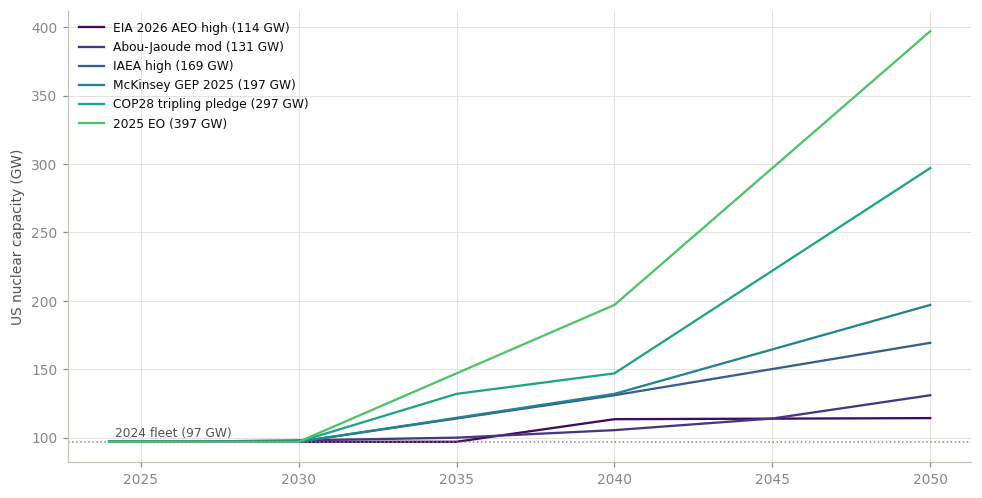

EIA 2026 AEO high: 114.3, 114.3 traditional, 381.0 SMR
Abou-Jaoude mod: 131.0, 131.0 traditional, 436.67 SMR
IAEA high: 169.3, 169.3 traditional, 564.33 SMR
McKinsey GEP 2025: 197.0, 197.0 traditional, 656.67 SMR
COP28 tripling pledge: 297.0, 297.0 traditional, 990.0 SMR
2025 EO: 397.0, 397.0 traditional, 1323.33 SMR


In [2]:
# The locked schedule set: capacity index by year, 2024-2050 (index 100 = 97.0 GW in 2024).
# Values are carried over unchanged from the reference notebook (v2.4 cell 3); only two
# names differ: "COP29 target" -> "COP28 tripling pledge", "Abou-Jaoude" -> "Abou-Jaoude mod".
US_GW_2024 = 97.0
# GW basis used EVERYWHERE (plots, experience counting, and the ReEDS mandate files):
# the index read as literal GW minus a flat 3 GW, undoing the rounding of the 97-GW 2024
# fleet up to index 100. So every schedule sits exactly 3 GW below its nominal targets
# (2025 EO: 397 GW in 2050) and starts at exactly the real 97-GW fleet.
OFFSET_GW = 3.0

US_SCHEDULES = {
    "EIA 2026 AEO high":     [100,100,100,100,100,100,100,100,100,100,100,100,103.3,106.6,109.9,
                              113.2,116.5,116.58,116.66,116.74,116.82,116.9,116.98,117.06,117.14,
                              117.22,117.3],
    "Abou-Jaoude mod":       [100,100,100,100.25,100.5,100.75,101,101.4,101.8,102.2,102.6,103,
                              104.1,105.2,106.3,107.4,108.5,110.2,111.9,113.6,115.3,117,120.4,
                              123.8,127.2,130.6,134],
    "IAEA high":             [100,100,100,100,100,100,100,103.4,106.8,110.2,113.6,117,120.4,123.8,
                              127.2,130.6,134,137.83,141.66,145.49,149.32,153.15,156.98,160.81,
                              164.64,168.47,172.3],
    "McKinsey GEP 2025":     [100,100,100,100,100,100,100,103.5,107,110.5,114,117.5,121,124.5,128,
                              131.5,135,141.5,148,154.5,161,167.5,174,180.5,187,193.5,200],
    "COP28 tripling pledge": [100,100,100,100,100,100,100,107,114,121,128,135,138,141,144,147,150,
                              165,180,195,210,225,240,255,270,285,300],
    "2025 EO":               [100,100,100,100,100,100,100,110,120,130,140,150,160,170,180,190,200,
                              220,240,260,280,300,320,340,360,380,400],
}
SCHED_ORDER = list(US_SCHEDULES)             # fixed order: ascending 2050 ambition, 117 -> 400

# Short machine-readable token per schedule - used in ReEDS file names and switch values
SCEN_TOKEN = {
    "EIA 2026 AEO high":     "eia_aeo_high",
    "Abou-Jaoude mod":       "abou_jaoude",
    "IAEA high":             "iaea_high",
    "McKinsey GEP 2025":     "mckinsey",
    "COP28 tripling pledge": "cop28",        # renamed from cop29 (see the markdown above)
    "2025 EO":               "eo2025",
}

for name, idx in US_SCHEDULES.items():
    assert len(idx) == T, name
    assert all(b >= a for a, b in zip(idx, idx[1:])), f"{name}: schedule must be non-decreasing"

# --- Read-and-compare: the fork's schedule table must equal the definition above ---
# (the development notebook exported this file; the public notebook never writes ReEDS inputs)
sched_def = pd.DataFrame({SCEN_TOKEN[name]: US_SCHEDULES[name] for name in SCHED_ORDER},
                         index=pd.Index(YEARS, name="year"))
US_SCHEDULES_CSV = paths.reeds_inputs() / "nuclear_learning" / "US_SCHEDULES.csv"
sched_file = pd.read_csv(US_SCHEDULES_CSV, comment="#", index_col="year")
assert list(sched_file.columns) == list(sched_def.columns), sched_file.columns
assert sched_file.index.tolist() == YEARS.tolist(), "US_SCHEDULES.csv must cover 2024-2050"
assert np.array_equal(sched_file.to_numpy(float), sched_def.to_numpy(float)), \
    "US_SCHEDULES.csv differs from the notebook's schedule definition"
print(f"{paths.rel(US_SCHEDULES_CSV)} equals the schedule definition (6 schedules x {T} years)")

# House schedule colors: the notebook's SCHED_ORDER is ambition-ordered, matching
# ps.SCHED_ORDER token for token (eia, aj, iaea, mck, cop28, eo).
SCHED_COLOR = {name: ps.SCHED_C[tok] for name, tok in zip(SCHED_ORDER, ps.SCHED_ORDER)}

# --- Plot: the ambition ladder in GW (literal GW minus the 3-GW rounding offset) ---
fig, ax = plt.subplots(figsize=(ps.W2, 4.6))
for name in SCHED_ORDER:
    ax.plot(YEARS, np.array(US_SCHEDULES[name]) - OFFSET_GW, color=SCHED_COLOR[name],
            label=f"{name} ({US_SCHEDULES[name][-1] - OFFSET_GW:.0f} GW)")
ax.axhline(US_GW_2024, ls=":", c=ps.FAINT, lw=1)
ax.text(2024.2, US_GW_2024 + 4, "2024 fleet (97 GW)", fontsize=8, color=ps.MUTED)
ax.set_ylabel("US nuclear capacity (GW)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
for key in US_SCHEDULES.keys():
    print(f"{key}: {US_SCHEDULES[key][-1] - OFFSET_GW}, {US_SCHEDULES[key][-1] - OFFSET_GW} traditional, {np.round((US_SCHEDULES[key][-1] - OFFSET_GW)/.3, 2)} SMR")

In [3]:
# Regeneration parity check: the mandate trajectory files already in the ReEDS fork must
# equal what _generate_cap_trajectories.py would produce from the export above -
# MW = (index - 3.0) * 1000, read as literal GW. A mismatch means a transcription drift
# between this notebook and the fork inputs, which would silently decouple the costs
# from the mandates they are supposed to be consistent with.
TRAJ_DIR = paths.reeds_inputs() / "nuclear_learning"

problems = []
for name in SCHED_ORDER:
    token = SCEN_TOKEN[name]
    path = TRAJ_DIR / f"nuclear_cap_trajectory_{token}.csv"
    rows = [ln.split(",") for ln in path.read_text().splitlines() if not ln.startswith("*")]
    on_file = {int(y): float(mw) for y, mw in rows}
    expected = {int(y): round((v - OFFSET_GW) * 1000.0, 1)
                for y, v in zip(YEARS, US_SCHEDULES[name])}
    if on_file != expected:
        diffs = {y: (on_file.get(y), expected[y]) for y in expected if on_file.get(y) != expected[y]}
        problems.append(f"{name} ({path.name}): {diffs}")
assert not problems, "trajectory parity check FAILED:\n" + "\n".join(problems)
print("trajectory parity check PASSED: all six ReEDS mandate files match the schedule export "
      f"(basis: literal GW minus {OFFSET_GW:.0f} GW, x1000 to MW)")

trajectory parity check PASSED: all six ReEDS mandate files match the schedule export (basis: literal GW minus 3 GW, x1000 to MW)


## 2 · Historical and foreign experience

Learning models run on *experience*: counts of reactors built. This section builds those counts
for the United States and ten world regions from the IAEA's unit-level reactor list (PRIS, as
published in the 2025 edition of *Nuclear Power Reactors in the World*, data through 31 December
2024). The loader asserts that the list reproduces the IAEA's own totals (417 operational, 62 under
construction); this is QA1.

Three rules turn the list into experience stocks:

1. **Builds, not net capacity.** Gross builds follow from the retirement identity: builds =
   capacity change + retirements. Retirements roll forward from each unit's grid-connection date
   under a uniform lifetime of 65 + 5u years. Here u (the *global deployment position*, a drawn
   input) places the world between the IAEA Low (u = 0) and High (u = 1) projections; the 65/70-year
   lives reproduce the IAEA's own 2024-fleet retirements in its two cases.
2. **The committed pipeline replaces the interpolated path through 2030.** Real units under
   construction fill 2025–2030. The pipeline is structurally zero after 2030, and experience before
   the 2030 anchor is handled by the anchor convention (Section 4), so the pipeline does not enter
   the post-2030 learning stocks.
3. **Foreign experience counts for less.** Each region r carries a transfer coefficient θ_r, a
   ceiling on cross-border knowledge flow derived from patent-citation barriers (Kim & Verdolini
   2023). A drawn scale s ∈ [0, 1] sets the level below the ceilings. Foreign units enter unsplit
   across reactor designs.

The US schedule enters the same way: post-2030 cumulative gross builds on the literal-GW-minus-3
basis, divided by the unit size (1 GW large reactor, 0.3 GW SMR).

In [4]:
# Non-US regional milestones (GW): 2024, 2030 Low/High, 2040 Low/High, 2050 Low/High
# (IAEA RDS-1 2025 projections + WNA/CNA). Regions: Canada, South America, Western Europe,
# Eastern Europe, Africa, West Asia, South Asia, Central+East Asia, Southeast Asia, Oceania.
REGION_MILESTONES = {
    "CA":  (12.7, 12.7, 12.7, 18.8, 23.0, 30.0, 63.7),
    "SAM": (5.1, 5, 5, 8, 11, 8, 20),
    "WEU": (95.4, 86, 92, 81, 114, 68, 136),
    "EEU": (53.6, 57, 57, 58, 82, 68, 103),
    "AF":  (1.9, 4, 5, 7, 12, 12, 30),
    "WA":  (5.8, 11, 11, 12, 20, 15, 35),
    "SA":  (11.1, 18, 22, 25, 43, 45, 85),
    "CEA": (94.5, 136, 144, 215, 264, 242, 328),
    "SEA": (0, 0, 0, 3, 7, 4, 18),
    "OC":  (0, 0, 0, 0, 0, 0, 2),
}
# Kim & Verdolini (2023)-derived knowledge-spillover ceilings (US as recipient)
THETA_KV = {"CA": 0.28, "SAM": 0.14, "WEU": 0.17794117647, "EEU": 0.1325, "AF": 0.16688725490,
            "WA": 0.13375, "SA": 0.185, "CEA": 0.135, "SEA": 0.16583333, "OC": 0.18}
REGIONS = list(THETA_KV.keys())

from nlpaper import pris_loader as pl   # the loader beside the ReEDS input generators

PRIS_UNITS = pl.load_units(str(pl.UNITS_CSV))
_milestones_2024 = {r: REGION_MILESTONES[r][0] for r in REGIONS} | {"US": US_GW_2024}
_issues = pl.validate_units(PRIS_UNITS[PRIS_UNITS["status"] == "operational"], _milestones_2024)
assert not _issues, _issues   # QA1: the data file must reproduce the IAEA's own totals

# Operational fleet (basis of the retirement identity) and the under-construction pipeline
FLEET = PRIS_UNITS[PRIS_UNITS["status"] == "operational"]
UC_UNITS = PRIS_UNITS[PRIS_UNITS["status"] == "under construction"]

def retirement_flow_gw(key, life_yr):
    """GW retiring per model year, from each unit's real grid-connection date + a lifetime rule."""
    return pl.retirement_schedule(FLEET, pd.Index(YEARS), lifetime_years=life_yr,
                                  region=key).to_numpy()

# Committed pipeline 2025-2030: real under-construction units (57 of 62 lack planned grid
# dates in RDS-2 and are estimated at construction start + 72 months). 2030 is the pipeline's
# real visibility horizon - the latest RDS-2 construction starts are 2024 - so it is
# structurally zero afterwards; and because post-anchor experience counting zeroes every year
# <= ANCHOR, the pipeline is inert for the learning stocks (kept as the documented
# committed-build anchor of the pre-2031 path).
PIPE_END = 2030
PIPELINE_GW = {r: pl.committed_pipeline(UC_UNITS[UC_UNITS["region"] == r],
                                        pd.Index(np.arange(2025, PIPE_END + 1)),
                                        lead_time_months=72).to_dict()
               for r in REGIONS}

# Historical experience base (for the "full-stock" convention, S5 Step 6): units EVER
# grid-connected. Under-construction units are excluded: 5 of them (Angra-3, Rajasthan-7,
# Kursk 2-1/2-2, Leningrad 2-3) carry PLANNED grid dates, which are not completed experience.
_ever = PRIS_UNITS[(PRIS_UNITS["status"] != "under construction")
                   & PRIS_UNITS["grid_connection"].notna()]
HIST_UNITS = {r: int((_ever["region"] == r).sum()) for r in REGIONS + ["US"]}

US_LICENSE_LIFE = 80.0   # yr - US subsequent-license-renewal trend; ~0 US retirements before 2050
ONE_FACTOR_DELTA = 0.0   # bounded regional noise on u (0 = one global u; variance-conservative)

print(f"PRIS fleet loaded: {len(FLEET)} operational, {len(UC_UNITS)} under construction "
      f"(validated against RDS-2 published totals and RDS-1 2024 milestones)")

PRIS fleet loaded: 417 operational, 62 under construction (validated against RDS-2 published totals and RDS-1 2024 milestones)


In [5]:
# Precompute the deployment-derived experience stocks that the OCC engine consumes.
def net_path_gw(region, u):
    """Regional net capacity path: interpolate the 2024/2030/2040/2050 milestones, positioned
    between Low and High by the global deployment draw u."""
    c = REGION_MILESTONES[region]
    vals = [c[0], c[1] + u*(c[2]-c[1]), c[3] + u*(c[4]-c[3]), c[5] + u*(c[6]-c[5])]
    return np.interp(YEARS, [2024, 2030, 2040, 2050], vals)

def gross_additions_gw(region, u):
    """The retirement identity: builds = max(0, capacity change + retirements); the committed
    pipeline REPLACES the interpolated path through PIPE_END = 2030 (real units; structurally
    zero after 2030, so it only shapes the pre-anchor record - see the S3 note)."""
    dnet = np.diff(net_path_gw(region, u), prepend=net_path_gw(region, u)[0])
    # Lifetimes are COUPLED to u because the IAEA builds its cases that way (low case: 156 GW
    # of the 2024 fleet retired by 2050; high case: LTO holds retirements to ~81 GW). 65/70-yr
    # uniform lives reproduce those totals from the RDS-2 vintages; the previous 60+20u
    # bracket retired 233/4 GW - roughly double the IAEA's own spread (recalibrated 2026-08-05).
    ret = retirement_flow_gw(region, 65.0 + 5.0*u)    # Low world <-> ~65-yr lives, High <-> ~70-yr
    g = np.clip(dnet + ret, 0.0, None)
    pipe_mask = YEARS <= PIPE_END
    g[pipe_mask] = [PIPELINE_GW[region].get(int(y), 0.0) for y in YEARS[pipe_mask]]
    return g

def post_anchor_cum(flow):
    """Cumulative builds counted from the 2030 anchor, END-of-year basis (experience before
    2030 is handled by the anchor convention, S5 Step 6). The one-year completion lag - a
    year's builds price only LATER years - is applied at the pricing boundary (lag1 in S5),
    so this stays a true cumulative for accounting (GW_ADDITIONS, mandate parity)."""
    x = flow.copy()
    x[YEARS <= ANCHOR] = 0.0
    return np.cumsum(x)

# Foreign SMR share of new capacity, IAEA RDS-1 2025: "Small modular reactors (SMRs) are
# estimated to account for 24% of the 676 GW(e) new capacity added by 2050 in the high case
# and for 5% of the 320 GW(e) new capacity added in the low case." The ENGINE consumes the
# unsplit stock - international experience enters the cross-firm channel, which does not
# distinguish designs (S5 Step 5) - so this share feeds only the ReEDS foreign-experience
# files' per-tech columns and the S14 own-routing sensitivity (which does split by tech).
SMR_FRAC_LO, SMR_FRAC_HI = 0.05, 0.24

def smr_frac(u):
    """Foreign SMR share of post-anchor gross additions at deployment position u."""
    return SMR_FRAC_LO + u*(SMR_FRAC_HI - SMR_FRAC_LO)

# REGION_STOCK[r][gi] = cumulative post-anchor units at u = U_GRID[gi] (unsplit, 1-GW basis)
REGION_STOCK = {}
for r in REGIONS:
    m_a = np.empty((len(U_GRID), T))
    for gi, u in enumerate(U_GRID):
        m_a[gi] = post_anchor_cum(gross_additions_gw(r, u)) / UNIT_FOREIGN_GW
    REGION_STOCK[r] = m_a

# US gross new-build units per schedule and technology (80-yr US life => retirements ~0)
US_RET = retirement_flow_gw("US", US_LICENSE_LIFE)
USN_NEW = {}     # USN_NEW[tech][schedule name] -> (T,) cumulative post-anchor new units
for tech in TECH:
    USN_NEW[tech] = {}
    for name in SCHED_ORDER:
        cap = np.array(US_SCHEDULES[name], float) - OFFSET_GW    # same GW basis as the mandate files
        dnet = np.diff(cap, prepend=cap[0])
        USN_NEW[tech][name] = post_anchor_cum(np.clip(dnet + US_RET, 0.0, None)) / TECH[tech]["unit_gw"]

print("US new-build units by 2050, per schedule (large / SMR):")
for name in SCHED_ORDER:
    print(f"  {name:22s} {USN_NEW['large'][name][-1]:6.0f} large   "
          f"{USN_NEW['smr'][name][-1]:6.0f} SMR")

US new-build units by 2050, per schedule (large / SMR):
  EIA 2026 AEO high          21 large       69 SMR
  Abou-Jaoude mod            36 large      121 SMR
  IAEA high                  76 large      252 SMR
  McKinsey GEP 2025         103 large      345 SMR
  COP28 tripling pledge     203 large      678 SMR
  2025 EO                   303 large     1011 SMR


## 3 · What is uncertain: the priors (Supplementary Table 1)

A *prior* is the distribution an uncertain input is drawn from. Each draw picks one value for every
row of the table below. Uniform ranges are a deliberate low-information choice: the empirical
record on nuclear learning rates spans an order of magnitude, and a peaked distribution would claim
knowledge that does not exist.

**The two reactor classes.** *Large* is a 1-GWe light-water reactor (the AP1000 class). *SMR* is a
300-MWe small modular reactor. Both classes share one drawn world; their inputs differ only in the
ranges below.

**Dependence.** A *Gaussian copula* (a device that ties several random draws together through
correlated normal variables) joins three *latent* axes: learning, anchor cost, and the global
deployment position u. The learning and anchor-cost latents have correlation −0.3 (the "moderate"
set: standardized programs start cheaper and learn faster). The two reactor classes share the
learning latent and the anchor-cost latent, so their learning rates are *comonotone* (one uniform
number sets both: high goes with high) and so are their anchor costs. Every other input is an
independent draw.

**O&M.** Fixed and variable O&M costs are not drawn. The ReEDS case exports (notebook 04) map them
from the anchor-cost latent over the ATB advanced-to-conservative range, so an expensive-anchor
world also carries high O&M.

**Scope limit.** The learning-rate ranges reproduce successful-program experience. Negative
learning (the French and US historical records) lies below the support by design; the hindcast in
Section 12 shows where history falls.

The next cell holds Supplementary Table 1 as data and exports it. Section 9 checks every stated
range against the 60,000 drawn worlds in `mc_perdraw.npz`; notebook 16 only formats the table.

In [6]:
# Supplementary Table 1 (the Monte Carlo variables) as data. The rows mirror the priors that
# draw_world (Section 4) implements; Section 9 verifies every stated support against the draws.
MC_PRIORS = [
    ("Learning rate, large reactors", "LR_large",
     "uniform, 3% to 12% per doubling",
     "learning latent (shared)",
     "firm-level rate; brackets Abou-Jaoude's 8%; low end: Grubler 2010, "
     "Eash-Gates 2020; high end: Lovering 2016, Barakah"),
    ("Learning rate, SMR", "LR_smr",
     "uniform, 3% to 16% per doubling",
     "learning latent (comonotone with large)",
     "firm-level rate; brackets Abou-Jaoude's 9.5% and the 5-15% SMR "
     "literature span (all assumptions; no empirical SMR rate exists)"),
    ("2030 anchor cost (BOAK), large", "BOAK_large",
     "uniform, 5,250 to 7,750 $/kW (2022 USD)",
     "anchor-cost latent (shared)",
     "Abou-Jaoude Table A-1; NREL ATB 2024"),
    ("2030 anchor cost (BOAK), SMR", "BOAK_smr",
     "uniform, 5,500 to 10,000 $/kW (2022 USD)",
     "anchor-cost latent (comonotone with large)",
     "Abou-Jaoude Table A-1; NREL ATB 2024"),
    ("Global deployment position", "u",
     "uniform, 0 (IAEA Low) to 1 (IAEA High)",
     "third copula latent",
     "IAEA RDS-1 2025 projection envelope; u also sets foreign fleet "
     "lifetimes (65 to 70 years)"),
    ("International spillover scale", "s",
     "uniform, 0 to 1; multiplies the regional theta ceilings",
     "independent",
     "Kim & Verdolini 2023 patent-citation barriers set the regional "
     "ranking; s sweeps the level from ambient transfer to the ceilings"),
    ("Cross-technology spillover", "x_ls, x_sl",
     "uniform, 0 to 0.30, each direction",
     "independent",
     "a drawn fraction of the other technology's domestic program also "
     "teaches this technology's vendors; capped well below own learning"),
    ("Vendor count", "m",
     "discrete uniform on {4, 5, 6, 7, 8}",
     "independent",
     "Abou-Jaoude's 4 vendors to the current 7+ US vendors"),
    ("Experience-base convention", "c",
     "fresh start (tiny base) or legacy fleet credited (full stock), "
     "probability 1/2 each",
     "independent",
     "structural (model-form) uncertainty; US large-reactor history "
     "counts for large only"),
    ("Channel substitution", "rho_CES",
     "discrete uniform on {-1, 0, 1}",
     "independent",
     "structural bracket around the multiplicative baseline (rho = 0)"),
    ("Construction-duration position", "lambda",
     "uniform, 0 (INL optimistic) to 1 (INL moderate)",
     "independent",
     "INL/RPT-25-84701 project-duration curves"),
    ("Construction-duration noise", "z",
     "one lognormal factor per world; sigma from the 21-unit panel "
     "residual",
     "independent",
     "realized dispersion of 2009-2024 Gen-III+ projects (PRIS/RDS-2)"),
    ("O&M costs (fixed and variable)", "FOM, VOM",
     "not drawn: mapped from the anchor-cost latent over the ATB "
     "advanced-to-conservative range",
     "comonotone with the anchor cost",
     "expensive-anchor worlds carry high O&M; never an independent "
     "sensitivity (ReEDS case exports)"),
]
st1 = pd.DataFrame(MC_PRIORS, columns=["input", "symbol", "prior", "dependence", "basis"])
assert len(st1) == 13, "Supplementary Table 1 has 13 rows (12 drawn inputs + the O&M mapping)"
st1.to_csv(EXPORTS / "st1_mc_variables.csv", index=False)
print(f"wrote {paths.rel(EXPORTS / 'st1_mc_variables.csv')} ({len(st1)} rows)")
st1

wrote analysis\results\exports\01\st1_mc_variables.csv (13 rows)


,input,symbol,prior,dependence,basis
0,"Learning rate, large reactors",LR_large,"uniform, 3% to 12% per doubling",learning latent (shared),firm-level rate; brackets Abou-Jaoude's 8%; lo...
1,"Learning rate, SMR",LR_smr,"uniform, 3% to 16% per doubling",learning latent (comonotone with large),firm-level rate; brackets Abou-Jaoude's 9.5% a...
2,"2030 anchor cost (BOAK), large",BOAK_large,"uniform, 5,250 to 7,750 $/kW (2022 USD)",anchor-cost latent (shared),Abou-Jaoude Table A-1; NREL ATB 2024
3,"2030 anchor cost (BOAK), SMR",BOAK_smr,"uniform, 5,500 to 10,000 $/kW (2022 USD)",anchor-cost latent (comonotone with large),Abou-Jaoude Table A-1; NREL ATB 2024
4,Global deployment position,u,"uniform, 0 (IAEA Low) to 1 (IAEA High)",third copula latent,IAEA RDS-1 2025 projection envelope; u also se...
5,International spillover scale,s,"uniform, 0 to 1; multiplies the regional theta...",independent,Kim & Verdolini 2023 patent-citation barriers ...
6,Cross-technology spillover,"x_ls, x_sl","uniform, 0 to 0.30, each direction",independent,a drawn fraction of the other technology's dom...
7,Vendor count,m,"discrete uniform on {4, 5, 6, 7, 8}",independent,Abou-Jaoude's 4 vendors to the current 7+ US v...
8,Experience-base convention,c,fresh start (tiny base) or legacy fleet credit...,independent,structural (model-form) uncertainty; US large-...
9,Channel substitution,rho_CES,"discrete uniform on {-1, 0, 1}",independent,structural bracket around the multiplicative b...


## 4 · The cost engine: how deployment becomes overnight cost

The engine turns one drawn world plus one schedule into an *overnight capital cost* (OCC: the cost
per kW of building a plant as if it were built overnight, i.e. excluding interest during
construction; 2022 $/kW) for every year 2024–2050.

**Learning model.** The engine follows the market-split learning model of Abou-Jaoude et al.
(2024, INL): *m* equal-share US vendors each learn from two experience stocks.

- The **own stock** O counts units of the vendor's own design. Each doubling of O cuts cost by the
  learning rate LR (a *firm-level* rate).
- The **cross-firm stock** A counts every other not-own-design unit: the other vendors' units, the
  θ·s-weighted foreign units (*spillover*: knowledge that crosses the firm wall and the national
  border), and a drawn fraction x of the *other* reactor class's US program. Each doubling of A cuts
  cost by only ω·LR, with ω = 1/3 (Irwin & Klenow 1994: firms learn about three times as much from
  their own output as from competitors').

**Starting-cost convention (the 2030 anchor).** The level of each cost curve is pinned at 2030 to
the drawn *BOAK* cost (best-of-a-kind: the published 2030 estimate, which prices a vendor's second
unit). Learning moves cost relative to that anchor, so the engine never needs the unknowable cost of
the first unit:

OCC(t) = BOAK × (E(t) / E(2030))^(−b),

where E combines O and A. The per-vendor base at the anchor is the inclusive Wright index 2 (one
completed first unit plus the BOAK unit itself). A drawn *experience-base convention* c decides
whether the historical US fleet also counts (large reactors only): c = 0 is a fresh start (tiny
base), c = 1 credits the legacy fleet (full stock). A one-year completion lag (`lag1`) makes each
year's builds price only later years.

**Channel substitution.** The engine combines O and A with a constant-elasticity-of-substitution
(CES) power mean of order ρ_CES ∈ {−1, 0, 1}. The weights and exponent follow from LR and ω, so the
ρ_CES → 0 member reproduces the plain two-power-law model exactly (QA6 asserts this).

**Two channels per reactor class.** The *full channel* gives the class the schedule's entire build
program. The *loser channel* (`_intl`) gives it no US program of its own: its cost moves only
through international spillover and the fraction x of the other class's program.

The derivation below states every step with its source. It is reference material; the code after
it is short, and its docstrings restate what matters.

### Derivation of the OCC equation (reference)

This section derives the engine equation step by step, assuming comfort with algebra and logarithms but **no economics background**. Variables are defined as they appear and collected in a table at the end; every equation is cited to its source. Throughout, "cost" means overnight capital cost (OCC, \$/kW in 2022 USD, excluding financing) and a "unit" is one completed reactor of the technology class being modeled.

#### Step 1 — Wright's law: cost falls by a fixed fraction per doubling of experience

The empirical starting point, first documented in aircraft manufacturing: **each time cumulative production doubles, unit cost falls by a roughly constant percentage** (Wright 1936). That percentage is called the *learning rate*, LR (terminology per Rubin et al. 2015). Writing $C(N)$ for the cost of the next unit after $N$ units have been built:

$$C(2N) = (1-\mathrm{LR})\,C(N) \tag{D1}$$

*(Wright 1936.)* To turn D1 into a formula, count doublings. If $N$ is $k$ doublings past a reference point $N_{\mathrm{ref}}$, then $k = \log_2(N/N_{\mathrm{ref}})$, and applying D1 $k$ times:

$$C(N) = C(N_{\mathrm{ref}})\,(1-\mathrm{LR})^{\log_2(N/N_{\mathrm{ref}})} = C(N_{\mathrm{ref}})\left(\frac{N}{N_{\mathrm{ref}}}\right)^{b}, \qquad b = \log_2(1-\mathrm{LR}) \tag{D2}$$

*(Wright 1936; the "experience curve" convention in energy analysis per IEA 2000.)* The last step uses the identity $a^{\log_2 x} = x^{\log_2 a}$ — take $\log_2$ of both sides; each equals $\log_2 a \cdot \log_2 x$. The exponent $b$ is negative: at LR = 8%, $b = \log_2(0.92) = -0.120$. Note that *doublings* do all the work — going from 2 to 4 units buys the same fractional cost reduction as going from 4,000 to 8,000 — which is why learning curves flatten so dramatically in absolute terms.

#### Step 2 — Not all units teach equally: own experience vs. other firms'

Using industry-total $N$ in D2 silently assumes a competitor's reactor teaches a vendor as much as its own. The classic empirical test (semiconductor manufacturing) found otherwise: **firms learn roughly three times as much from their own cumulative output as from other firms'** (Irwin & Klenow 1994). This splits experience into two stocks per vendor — own units $O$ and all other firms' units $A$ — each with its own exponent:

$$C = K \cdot O^{\,\log_2(1-\mathrm{LR})} \cdot A^{\,\log_2(1-\omega\mathrm{LR})}, \qquad \omega = \tfrac{1}{3} \tag{D3}$$

*(The ⅓ finding — and that spillovers cross national borders about as readily as they pass between domestic firms: Irwin & Klenow 1994. Their estimation is on price changes; the two-stock power-law rendering and the "(1 − LR/3) per doubling of others' units" implementation used here follow Abou-Jaoude et al. 2024, eq. (12).)* Reading D3: doubling your **own** stock cuts your cost by (1 − LR); doubling **everyone else's** stock cuts it by only (1 − ωLR) = (1 − LR/3). $K$ is an unknown constant (the first-unit cost scale) that Step 4 eliminates.

#### Step 3 — An equal m-vendor market: Abou-Jaoude's eq. (12), generalized

Abou-Jaoude et al. (2024) model the US advanced-reactor market as $m$ identical vendors with equal market shares (they fixed $m = 4$). If the industry builds $N$ units in total, each vendor builds $N/m$ of them, so in D3: $O = N/m$ and $A = (m-1)N/m$. Substituting gives their eq. (12) (printed in the report for $m=4$):

$$f(N) = \frac{1}{1-\mathrm{LR}}\,(1-\mathrm{LR})^{\log_2(N/4)}\,(1-\mathrm{LR}/3)^{\log_2(3N/4)} \tag{D4}$$

*(Abou-Jaoude et al. 2024, eq. (12).)* This notebook generalizes the hard-coded 4 to a drawn $m \in \{4,\dots,8\}$ — same equation with $N/4 \to N/m$ and $3N/4 \to (m-1)N/m$.

#### Step 4 — Anchoring: swap the unknown constant for the known 2030 cost

We never know $K$, but we do have 2030 **BOAK** cost estimates (Abou-Jaoude Table A-1; ATB 2024). Their anchor convention is *BOAK = 2OAK*: BOAK is the cost of a vendor's **second** unit (Abou-Jaoude et al. 2024, eq. (10)) — note this is a *vendor-level* statement. So the anchor sits at **inclusive Wright index 2** on each vendor's curve: one completed
FOAK plus the BOAK itself, the unit whose cost the 2030 estimate quotes. $O_0 = 2$ is that
index, **not** a count of two completed units — the convention embeds exactly *one*
completed build per vendor. With the entering-year lag (`lag1`), the state variable
$O(t) = O_0 + N^{US}(t)/m$ is then exactly the inclusive index of the unit currently being
built (completed predecessors plus one), so the anchored ratio prices every unit at its own
curve position. Unit-by-unit check (LR 10%, FOAK \$10{,}000,
BOAK \$9{,}000, one completed FOAK, one build per year; true Wright costs of units 2/3/4
are \$9{,}000 / \$8{,}462 / \$8{,}100): the engine at $O_0 = 2$ reproduces all three
*exactly*, while the superficially "exclusive" $O_0 = 1$ gives \$9{,}000 / \$8{,}100 /
\$7{,}615 — it prices unit $N$ at $C(2(N-1))$, asymptotically one full doubling of excess
learning, re-earning the FOAK→BOAK decline already embedded in the BOAK price. In a
ratio-form engine the base must be the inclusive index of the anchor-cost unit.
*(Physical identity of the completed unit: each vendor
deploys an experimental SMR in partnership with INL before its first grid-connected
build — PRISM-2 preceding the Natrium plant, and the experimental reactors built and
deployed under the 2025 executive order — so at the anchor each vendor holds exactly
one completed unit, and its first grid-connected build is unit 2, the unit the BOAK
estimate prices. Counting that experimental unit is also what reconciles the report's
executive-summary naming, which calls the first grid demonstration "FOAK": with the
experimental unit as unit 1, the 2030 grid builds price at BOAK = 2OAK rather than
FOAK. Unit-exact accounting was ratified on this two-part basis — the report's own
eq. (10) derivation plus this unit-1 story; the applied-attachment fork in the
report's published tables and the dual-convention sensitivity are pinned by QA4/QA4b
(Section 12) and by notebook 02.)* In a
symmetric market where every vendor is at the same point, the other $m-1$ vendors
contribute $A_0 = 2(m-1)$. Dividing D3 at time $t$ by D3 at 2030 cancels $K$:

$$\frac{C(t)}{\mathrm{BOAK}} = \left(\frac{O(t)}{O(2030)}\right)^{\log_2(1-\mathrm{LR})}\left(\frac{A(t)}{A(2030)}\right)^{\log_2(1-\omega\mathrm{LR})} \tag{D5}$$

With $N^{US}(t)$ post-2030 gross US builds (Section 2) split equally, $O(t) = 2 + N^{US}(t)/m$ and $A(t) = 2(m-1) + (m-1)N^{US}(t)/m$. Both ratios then equal $1 + N^{US}(t)/2m$, so the domestic-only model collapses to:

$$\frac{C(t)}{\mathrm{BOAK}} = \Big[(1-\mathrm{LR})(1-\omega\mathrm{LR})\Big]^{\log_2\!\left(1 + N^{US}(t)/2m\right)} \tag{D6}$$

Two consequences worth internalizing:
- **LR is a firm-level rate.** When the whole fleet doubles, every stock doubles, so industry-level cost falls by $(1-\mathrm{LR})(1-\omega\mathrm{LR})$ per fleet doubling — an effective industry learning rate of $1-(1-\mathrm{LR})(1-\omega\mathrm{LR}) \approx 1.3\,\mathrm{LR}$. Quoting the firm and industry rates interchangeably is a factor-of-1.3 error.
- **The anchor must be per-vendor for the market split to matter.** Suppose instead you pooled experience into one stock scaled by a market-structure factor, $E = \kappa\,(2 + N^{US})$. Then $E(t)/E(2030) = (2+N^{US})/2$ and $\kappa$ cancels — anchoring erases any pure *level* factor. In D6 the split survives only because $m$ sits *inside* the stock ($N^{US}/m$ accumulating against the fixed per-vendor base of 2). This is why an earlier revision of the reference notebook showed no vendor-count sensitivity.

#### Step 5 — International spillover: θ·s-weighted foreign units join the CROSS-FIRM stock

Foreign reactors also teach US vendors, but through *two* boundaries: the firm wall and the national border. Each region $r$'s post-2030 gross builds are weighted by a transfer coefficient $\theta_r \in [0,1]$, derived from patent-citation knowledge-flow estimates (Kim & Verdolini 2023, processed into the θ vector in the project workbook), and scaled by a drawn factor $s \in [0,1]$:

$$S^{KV}(t) = \sum_r \theta_r\,N_r(t), \qquad \text{entering the model as } s\,S^{KV}(t) \tag{D7}$$

*(Additive weighted "effective experience" stocks are the standard multi-region convention in energy-system models: IEA 2000; Barreto & Kypreos 2004.)* **Where the weighted units go.** Kim & Verdolini's diffusion parameter is normalized to the *domestic inter-firm* citation baseline: self-citations (same assignee) are excluded from every flow (their Table 1), and $\hat\Phi_{ij}$ is the probability that an inventor in country $i$ cites a patent from country $j$ *relative to the probability of citing a domestic patent* ($\hat\Phi_{ii} \equiv 1$ by construction — their eq. (5)). The firm boundary therefore already sits in θ's denominator: θ prices only the *extra* national border on top of the domestic cross-firm baseline. The normalization-consistent placement of $s\,\theta$-weighted foreign units is the **cross-firm stock $A$** — ω once for the firm wall, θ once for the border. Routing them into the own stock instead would credit foreign learning at roughly $1/\omega \approx 3\times$ what the K&V measurement supports at the margin; that variant survives in Section 11 as a deliberate structural *upper bound*, because patent citations cannot see licensing-scale transfer (K&V ignore jointly-filed patents and flag nuclear as uncovered by their technology classes) and licensing was historically nuclear's dominant international channel (Westinghouse→France, Combustion Engineering→Korea).

**What θ·s is — and is not.** It is *not* an estimate of international experience spillover for nuclear. It is a structured prior on cross-border knowledge **friction**: the regional *ranking* is borrowed from patent-citation barriers, the *level* is swept by $s$. The construct gap is stated plainly: citation flows measure the diffusion of codified invention knowledge, the model needs tacit experience spillover, and the two plausibly share barrier *structure*, not levels. The anchors: at $s \to 0$ international learning is ambient and weak, consistent with the observed non-convergence of national nuclear costs (Zimmerman 1982; Lester & McCabe 1993; Berthélemy & Escobar-Rangel 2015); at $s \to 1$ transfer approaches the θ ceilings. The international term gets no multiplicative factor of its own: a third power law anchored on its own small base would multiply in another complete learning curve and double-count cheap early doublings. And the foreign stock enters **unsplit across technologies**: the cross-firm channel does not distinguish designs — a not-own-design unit is a not-own-design unit — so the IAEA's SMR share of foreign additions (5% Low → 24% High) feeds only the ReEDS input files and the own-routing sensitivity (Section 11), never the engine.

#### Step 5′ — Cross-technology spillover: a drawn fraction x, in the cross-firm stock

Cross-*technology* experience (an AP1000 teaching SMR vendors, and vice versa) was previously zero by convention. It is now a drawn fraction per direction, $x_{L\to S}, x_{S\to L} \sim U(0, 0.30)$, independent — mirroring the mixed-build companion notebook: a fraction $x$ of the other technology's **domestic program** $N^{US}_{oth}$ joins the
cross-firm stock $A$, learning at ω·LR like any other not-own-design experience. Because
stocks count units, a gigawatt of SMR program contributes $1/0.3 \approx 3.3\times$ the
units of a gigawatt of large program — per-GW cross-tech spillover is tech-asymmetric by
construction, the per-unit convention applied consistently. No separate foreign cross-tech term exists: foreign units of both technologies are already inside the unsplit $S^{KV}$ (Step 5), and adding one would double-count them. The US historical fleet stays excluded from the cross-tech channel entirely — the empirical SMR learning-rate range already embeds any benefit of prior LWR construction (Step 6).

#### Step 6 — How much experience exists at the anchor? A structural convention

There are two defensible answers to "what has a vendor already learned by 2030?", and the gap between them is large, so both are carried as a drawn convention flag $c \in \{0,1\}$ (50/50):

- **Tiny base** ($c=0$): a genuinely new design restarts its curve — the vendor's base is just the BOAK anchor
  index of 2 (one completed FOAK plus the BOAK itself; Abou-Jaoude et al. 2024 convention).
- **Full stock** ($c=1$): reactor-building capability is generic, so the historical record counts — the standard experience-curve convention of accumulating from the technology's origin (IEA 2000; Rubin et al. 2015). Each vendor inherits its share $H^{US}/m$ of the historical US units (135 ever
  grid-connected, 116.9 GW — average 866 MW; counted as raw units on the per-unit
  convention: the project, not its megawatts, is the experience quantum), and the cross-firm stock inherits the θ-weighted historical world stock $H^{KV} = \sum_r \theta_r H_r$.

$$O_0 = 2 + c\,\frac{H^{US}}{m}, \qquad A_0 = (m-1)\,O_0 + s\,c\,H^{KV} \tag{D8}$$

where $H^{KV} = \sum_r \theta_r H_r$ is the θ-weighted historical world stock, entering
the cross-firm stock at weight $s$ for both technologies alike (Step 5's unsplit
convention).

One conservatism is carried knowingly: the ~62 foreign units under
construction — mostly completing before 2030 — are counted in neither $H^{KV}$ nor the
post-anchor flows (the committed pipeline is blanked at the anchor, Section 2), understating the
2030 cross-firm base by roughly 10% of $H^{KV}$ and steepening post-2030 foreign-driven
learning by about one point of 2050 OCC (a pipeline-base sensitivity in the development record
measured +0.5 % large and +1.1 % SMR at the 2050 median);
it is bracketed by the same structural dial ($c$) that excludes the entire historical stock
in tiny-base worlds, and is documented rather than corrected.

**Technology asymmetry (D8′).** The convention describes *where each technology sits on its own
learning curve at the shared BOAK anchor* — it never changes the anchor cost itself. And the US
historical fleet is ~140 **large light-water reactors**; no SMR has ever been built. So $H^{US}$
enters D8 **for large reactors only**: under full-stock, large nuclear sits at the flat end of its
curve (mature — most of its learning is already banked, as the Vogtle-era record suggests), while
SMRs keep their 2-unit base and stay at the steep start under *both* conventions. Two reasons SMRs
get no share of the US stock: (i) the drawn SMR learning-rate range (3–16%) comes from estimates
grounded in real-world build experience, so any benefit SMRs derive from prior LWR construction is
already embedded in those rates — adding the stock would double-count it; (ii) post-anchor
cross-technology flows are priced explicitly by the drawn $x$ (Step 5′), and granting the historical
stock on top would credit the same channel twice. The θ-weighted *foreign* historical stock $H^{KV}$
(all large LWRs) is not-own-design experience for both technologies and enters the cross-firm
stock at weight $s$ under full-stock (Step 5). A consequence worth noting: full-stock worlds are
where large nuclear is *most* disadvantaged relative to SMRs — its curve is flat while theirs
stays steep.

#### Step 7 — Assemble

Putting D5–D8 together, for Monte Carlo draw $d$ (which fixes $\mathrm{LR}_d$, $\mathrm{BOAK}_d$, $m_d$, $s_d$, $x_d$, $c_d$, and the deployment world behind the $S^{KV}_{d}$ stock — while $N^{US}$ is the *schedule's*, fixed for the whole MC):

$$\boxed{\;\mathrm{OCC}_d(t) = \mathrm{BOAK}_d \left(\frac{O_d(t)}{O_{0,d}}\right)^{\log_2(1-\mathrm{LR}_d)} \left(\frac{A_d(t)}{A_{0,d}}\right)^{\log_2(1-\omega\mathrm{LR}_d)}\;} \tag{D9}$$

$$O_d(t) = O_{0,d} + \frac{N^{US}(t)}{m_d}, \qquad A_d(t) = (m_d-1)\,O_{0,d} + \frac{(m_d-1)}{m_d}N^{US}(t) + s_d\big(c_d H^{KV} + S^{KV}_d(t)\big) + x_d\,N^{US}_{oth}(t)$$

($N^{US}_{oth}$ is the *other* technology's domestic program — zero for a technology holding the whole program, the winner's schedule for the loser trajectory of Sections 7 and 9. Foreign experience is non-rival, so it is never divided by $m$.)

At $t = 2030$ both parenthesized ratios equal 1 by construction, so $\mathrm{OCC}_d(2030) = \mathrm{BOAK}_d$ exactly for every draw (asserted in Section 12, QA2), and at $s_d = 0$, $c_d = 0$ the model reduces exactly to re-anchored generalized eq. (12), i.e., D6 (also asserted).

**Worked example** (large). Take $m = 5$ vendors, LR = 8% ($b_{own} = -0.120$, $b_{cross} = \log_2(1-0.08/3) = -0.039$), $s = 0.4$, tiny base ($c=0$), no other-technology program ($N^{US}_{oth} = 0$), and suppose by 2040 the US has built $N^{US} = 20$ large units and the θ-weighted foreign stock is $S^{KV} = 18$. Then $O_0 = 2$, $O = 2 + 20/5 = 6$ (ratio 3.0); $A_0 = 4 \times 2 = 8$, $A = 8 + \tfrac{4}{5}(20) + 0.4(18) = 31.2$ (ratio 3.9). So $\mathrm{OCC}/\mathrm{BOAK} = 3.0^{-0.120} \times 3.9^{-0.039} = 0.876 \times 0.948 = 0.83$ — a 17% real cost reduction from 2030. Setting $s = 0$ isolates the international contribution: the cross-firm ratio falls back to 3.0 and $\mathrm{OCC}/\mathrm{BOAK} = 0.876 \times 0.958 = 0.84$, so in this draw the θ-weighted foreign fleet is worth about one point of reduction — international learning is deliberately weak in the production engine, priced at the K&V-consistent double boundary (ω for the firm wall, θ for the border). The own-routing sensitivity (Section 11) brackets how much more the citation-invisible licensing channel could add: the same draw under own-channel routing reaches $\approx 0.77$.

#### Step 8 — What the two-channel structure assumes about substitutability, and a family that relaxes it

**Two classical answers to the same gap.** Wright's law (D1–D2) has *one* experience stock; it is silent on how two stocks should combine. The literature offers two answers, and D9 quietly uses both:

- *Multiplicative* (used across O and A in D3/D9): assume each stock has its own constant elasticity, independent of the other — $\partial^2 \ln C/\partial \ln O\,\partial \ln A = 0$ — and integrating that total differential gives the product of two power laws. Its economic microfoundation is **absorptive capacity**: the ability to exploit outside knowledge is itself conditioned on the internal knowledge base (Cohen & Levinthal 1989, 1990). Note its pathology: as $O \to 0$ the predicted cost diverges — the form cannot represent pure technology import, and the per-vendor anchor base of 2 units is what keeps this engine away from that singularity.
- *Additive* (used inside A in D7): leave Wright's one-stock law untouched and add a **measurement rule** for its stock,
$$E = O + \varphi A \tag{D10}$$
Its microfoundation is **random search** (Muth 1986): if each build is a draw from a distribution of techniques and cost is the best draw so far, then observing a fraction $\varphi$ of other firms' draws makes the effective draw count literally $O + \varphi A$, and the same extreme-value argument that gives Wright's power law applies to $E$ with no further assumptions.

**A family both emerge from.** Replace the aggregator with the weighted power mean (Hölder mean) of order $\rho_{CES}$ — the constant-elasticity-of-substitution (CES) form (Arrow, Chenery, Minhas & Solow 1961):

$$E = \big(w\,O^{\rho_{CES}} + (1-w)\,A^{\rho_{CES}}\big)^{1/\rho_{CES}}, \qquad \mathrm{OCC} = \mathrm{BOAK}\left(\frac{E(t)}{E(2030)}\right)^{-b} \tag{D11}$$

with $\sigma = 1/(1-\rho_{CES})$ the elasticity of substitution between the channels. Both earlier forms are members:

- **$\rho_{CES} = 1$:** $E = wO + (1-w)A$ — the additive rule D10 with $\varphi = (1-w)/w$ (the leftover factor $w$ cancels in the anchored ratio $E(t)/E(2030)$).
- **$\rho_{CES} \to 0$:** write $\ln E = \ln\!\big(w e^{\rho \ln O} + (1-w) e^{\rho \ln A}\big)/\rho$ and apply L'Hôpital — legitimate only because the numerator $\to \ln(w + (1-w)) = \ln 1 = 0$, which is why the weights **must be normalized** (unnormalized weights leave a constant $>1$ in the bracket and $E$ diverges). The limit is $\ln E = w \ln O + (1-w)\ln A$: the geometric mean $E = O^w A^{1-w}$, i.e., the multiplicative form.

Matching the $\rho_{CES}\to 0$ member to D9 exactly fixes the two shape parameters — they are **not new free parameters**:

$$(E/E_0)^{-b} = (O/O_0)^{-bw}(A/A_0)^{-b(1-w)} \;\equiv\; (O/O_0)^{\beta_1}(A/A_0)^{\beta_2} \;\Rightarrow\; b = -(\beta_1+\beta_2), \quad w = \frac{\beta_1}{\beta_1+\beta_2} \tag{D12}$$

with $\beta_1 = \log_2(1-\mathrm{LR}) < 0$ and $\beta_2 = \log_2(1-\omega\mathrm{LR}) < 0$, so $b > 0$ and $w \in (0,1)$. One constraint comes with the family: degree-1 homogeneity of $E$ forces the implied channel exponents to sum to $-b$ — the family nests the *constrained* multiplicative form. That is exactly the form this engine already uses ($\beta_1 + \beta_2$ pinned by LR and ω), so nothing is lost by the generalization.

**Fractional orders.** $\rho_{CES}$ interpolates the classical means:

| $\rho_{CES}$ | mean | $\sigma$ | reading |
|---|---|---|---|
| 1 | arithmetic | ∞ | fixed exchange rate between channels — the pooled additive stock |
| ½ | — | 2 | mild substitutes |
| → 0 | geometric | 1 | **status quo** (D9): channel contribution shares held constant |
| −1 | harmonic | ½ | complements: cross-firm value decays as it outruns the own base |
| → −∞ | min(O, A) | 0 | pure bottleneck: cross-firm experience beyond the own-design base is worthless |

$\rho_{CES} = 0$ is the only removable singularity; for $\rho_{CES} < 0$ the outer exponent $1/\rho_{CES}$ flips sign, which the log-domain implementation sidesteps. One caution on reading $w$: it is literally the learning *share* only at $\rho_{CES} = 0$ — in general the own-channel share is $wO^{\rho}/(wO^{\rho} + (1-w)A^{\rho})$, which depends on the mix.

**What σ means here.** As the cross-firm stock grows relative to the vendor's own-design stock, how fast does its marginal learning value decay? $\sigma = \infty$: never (every θ-discounted foreign unit keeps its full exchange rate). $\sigma = 1$ (status quo): exactly fast enough that each channel's contribution share stays constant. $\sigma < 1$: faster — graded absorptive capacity, where foreign-heavy experience buys progressively less without a matching domestic base. $\sigma = 0$: nothing beyond the own-design bottleneck counts.

**Why sweep it.** The multiplicative choice in D3 was a functional-form convention, not an estimate, and $\rho_{CES}$ is not identifiable from available nuclear data — learning-model coefficients are weakly identified even where data are rich, and misspecification biases them toward optimism (Nordhaus 2014). The sweep therefore *brackets a structural assumption* rather than estimating a parameter, in the same spirit as the experience-base convention — which is also why the grid is **symmetric about the status-quo σ = 1** ({−1, 0, +1}; revised 2026-08-06 from {−2, −1, 0, 1}, whose second complements member put half the sweep's mass on regimes that bottleneck everything behind the own-design base — a tilt, not a bracket). The **inner** pools stay additive ($\rho = 1$): Irwin & Klenow found spillovers cross national borders about as readily as they pass between domestic firms. The complements member then expresses genuine absorptive-capacity limits between the own-design and not-own-design pools — foreign-heavy cross-firm experience buys progressively less without a matching own-design base — which is exactly the structural question the sweep is meant to bracket.

**Variable reference.**

| Symbol | Meaning | Units | Where it is set |
|---|---|---|---|
| $\mathrm{OCC}_d(t)$ | overnight capital cost, draw $d$, year $t$ | \$/kW (2022 USD) | model output |
| $\mathrm{BOAK}_d$ | 2030 anchor cost (vendor's 2nd unit) | \$/kW (2022 USD) | drawn; Abou-Jaoude Table A-1 / ATB 2024 ranges |
| $\mathrm{LR}_d$ | firm-level learning rate | – | drawn; U(3%,12%) large, U(3%,16%) SMR |
| $\omega$ | cross-firm learning fraction | – | ⅓, fixed (Irwin & Klenow 1994) |
| $m_d$ | number of equal-share US vendors | – | drawn; discrete U{4,…,8} |
| $N^{US}(t)$ | post-2030 cumulative gross US builds | units | the schedule (fixed per MC) + retirement identity |
| $O_d(t),\,O_{0,d}$ | vendor's own-design experience stock; its 2030 value | units | eqs. D8/D9 |
| $A_d(t),\,A_{0,d}$ | cross-firm experience stock (other vendors + international); its 2030 value | units | eqs. D8/D9 |
| $\theta_r$ | cross-border knowledge-friction coefficient, region $r$ (normalized to the domestic inter-firm baseline) | – | Kim & Verdolini (2023)-derived ceilings; ranking retained, level swept by $s$ |
| $s_d$ | international friction level (position below the θ ceilings) | – | drawn; U(0,1) |
| $x_d$ ($x_{L\to S}$, $x_{S\to L}$) | incoming cross-technology spillover fraction | – | drawn; U(0, 0.30) each direction (Step 5′) |
| $N_r(t)$ | post-2030 cumulative gross builds, region $r$ | units | IAEA Low/High position $u_d$ + retirement identity |
| $S^{KV}_{d}(t)$ | θ-weighted foreign experience stock (unsplit across technologies) | units | eq. D7 |
| $H^{US},\,H_r,\,H^{KV}$ | historical units ever built (US; region $r$; θ-weighted world) | units | PRIS/RDS-2 data (Section 2); $H^{US}$ applies to large only (D8′) |
| $c_d$ | experience-base convention flag (0 tiny, 1 full-stock) | – | drawn; 50/50 |
| $\rho_{CES,d}$ | channel-substitution parameter (order of the outer power mean) | – | drawn; discrete uniform over {−1, 0, 1} |
| $\sigma$ | elasticity of substitution between channels, $1/(1-\rho_{CES})$ | – | derived from $\rho_{CES}$ |
| $E_d(t)$ | CES-aggregated experience index | units | eq. D11 |
| $w_d,\,b_d$ | CES weight and curve exponent | – | derived from LR$_d$ and ω (eq. D12) — not free parameters |

**Sources cited in this derivation.**
- Wright, T.P. (1936). "Factors Affecting the Cost of Airplanes." *Journal of the Aeronautical Sciences* 3(4), 122–128. — D1, D2.
- IEA (2000). *Experience Curves for Energy Technology Policy.* OECD/IEA, Paris. — experience-curve convention; additive multi-region stocks; full-stock convention.
- Rubin, E.S., Azevedo, I.M.L., Jaramillo, P., Yeh, S. (2015). "A review of learning rates for electricity supply technologies." *Energy Policy* 86, 198–218. — LR terminology; learning-rate dispersion motivating the uniform draws.
- Irwin, D.A., Klenow, P.J. (1994). "Learning-by-Doing Spillovers in the Semiconductor Industry." *Journal of Political Economy* 102(6), 1200–1227. — the ω ≈ ⅓ finding and its cross-border strength.
- Abou-Jaoude, A., et al. (2024). *Meta-Analysis of Advanced Nuclear Reactor Cost Estimations* (INL/RPT-24-77048). Idaho National Laboratory. — eq. (10) BOAK = 2OAK anchor; eq. (11)/(12) market-split learning; BOAK ranges.
- Kim & Verdolini (2023). *Energy Strategy Reviews* 49, 101151. Cross-country knowledge-diffusion estimates from patent citations (wind, solar, efficient fossil; self-citations excluded — their Table 1; flows normalized to the domestic citation baseline — their eq. (5)), as processed into the θ vector in the project workbook. — D7 weights; the Step 5 placement.
- Barreto, L., Kypreos, S. (2004). "Endogenizing R&D and market experience in the 'bottom-up' energy-systems ERIS model." *Technovation* 24(8), 615–629. — additive effective-experience convention (D7).
- Zimmerman, M.B. (1982). "Learning Effects and the Commercialization of New Energy Technologies: The Case of Nuclear Power." *Bell Journal of Economics* 13(2), 297–310; Lester, R.K., McCabe, M.J. (1993). "The Effect of Industrial Structure on Learning by Doing in Nuclear Power Plant Operation." *RAND Journal of Economics* 24(3), 418–438; Berthélemy, M., Escobar-Rangel, L. (2015). "Nuclear reactors' construction costs: The role of lead-time, standardization and technological progress." *Energy Policy* 82, 118–130. — firm/design-specificity of nuclear learning (Step 5 rate cap).
- Cohen, W.M., Levinthal, D.A. (1989). "Innovation and Learning: The Two Faces of R&D." *The Economic Journal* 99(397), 569–596; and (1990). "Absorptive Capacity: A New Perspective on Learning and Innovation." *Administrative Science Quarterly* 35(1), 128–152. — absorptive-capacity microfoundation of the multiplicative form (Step 8).
- Muth, J.F. (1986). "Search Theory and the Manufacturing Progress Function." *Management Science* 32(8), 948–962. — random-search microfoundation of the additive measurement rule (D10).
- Arrow, K.J., Chenery, H.B., Minhas, B.S., Solow, R.M. (1961). "Capital-Labor Substitution and Economic Efficiency." *Review of Economics and Statistics* 43(3), 225–250. — the CES functional form and σ (D11).
- Nordhaus, W.D. (2014). "The Perils of the Learning Model for Modeling Endogenous Technological Change." *The Energy Journal* 35(1), 1–13. — identification critique of learning coefficients; why ρ_CES is swept, not fitted (Step 8).

In [7]:
# The parameter draw and the OCC engine. One draw = one internally consistent "world"
# shared by both technologies. Per-trajectory architecture: draw_world knows NOTHING
# about schedules - the schedule enters later as the n_us argument to the engine.
RHO_SETS = {"zero": 0.0, "moderate": -0.3, "strong": -0.6}   # lr <-> boak correlation (a judgment,
                                                             # swept in S14; the reference notebook's
                                                             # sched<->u entry died with the schedule draw)
LATENTS = ["lr", "boak", "u"]

def corr_matrix(rho_key):
    C = np.eye(3)
    C[0, 1] = C[1, 0] = RHO_SETS[rho_key]
    ev = np.linalg.eigvalsh(C)
    assert ev.min() > 1e-10, f"correlation matrix '{rho_key}' is not positive definite: {ev}"
    return C

def draw_world(n, rho_key, rng):
    """Draw n worlds: every uncertain input of S4's table, one row per draw.

    A Gaussian copula joins the three latent axes (learning, anchor cost, global deployment
    position u): LR and BOAK are modestly negatively correlated under the default set
    (standardized programs start cheaper AND learn faster). The remaining inputs are
    independent draws. The duration inputs (lambda, z) are drawn here too, so a world is
    complete in one call and no random stream is shared between components.
    """
    Z = rng.standard_normal((n, 3)) @ np.linalg.cholesky(corr_matrix(rho_key)).T
    U = stats.norm.cdf(Z)                                   # Gaussian copula -> uniforms
    w = pd.DataFrame(index=range(n))
    for tech in TECH:
        t = TECH[tech]
        w[f"lr_{tech}"] = t["lr_lo"] + U[:, 0]*(t["lr_hi"] - t["lr_lo"])      # comonotone across techs
        w[f"boak_{tech}"] = t["boak_lo"] + U[:, 1]*(t["boak_hi"] - t["boak_lo"])
    w["u"] = U[:, 2]                                        # global deployment position
    w["s"] = rng.uniform(0.0, 1.0, n)                       # spillover scale
    w["n_vendors"] = rng.integers(4, 9, n)                  # vendor count m
    w["conv_full"] = rng.integers(0, 2, n)                  # 0 = tiny-base, 1 = full-stock
    w["ces_rho"] = rng.choice(CES_RHO_GRID, size=n)         # channel-substitution stratum
    w["dur_lambda"] = rng.uniform(0.0, 1.0, n)              # duration scenario position (S6)
    w["dur_z"] = rng.standard_normal(n)                     # persistent duration project noise (S6)
    w["x_ls"] = rng.uniform(0.0, X_SPILL_MAX, n)            # cross-tech spillover: large -> SMR
    w["x_sl"] = rng.uniform(0.0, X_SPILL_MAX, n)            # cross-tech spillover: SMR -> large
    return w

H_ALL_W = sum(THETA_KV[r]*HIST_UNITS[r] for r in REGIONS)   # theta-weighted historical foreign stock
OTHER_TECH = {"large": "smr", "smr": "large"}
X_IN_COL = {"large": "x_sl", "smr": "x_ls"}     # incoming cross-tech fraction, per receiving tech

def lag1(a):
    """One-year completion lag along the time axis: the stock ENTERING year t is the builds
    completed through t-1. Cumulative arrays (REGION_STOCK, USN_NEW) stay end-of-year for
    accounting; the lag is applied here, at the pricing boundary - without it the first
    post-anchor cohort would price on its own not-yet-built units (below BOAK)."""
    a = np.asarray(a, float)
    out = np.zeros_like(a)
    out[..., 1:] = a[..., :-1]
    return out

def experience_channels(world, tech, n_us, n_oth=None):
    """The two experience stocks O_d(t) (own) and A_d(t) (cross-firm), each (n_draws, T).

    n_us:  the schedule's cumulative post-anchor US builds of THIS technology, shape (T,) -
           or zeros for the loser trajectory (S10): same drawn world, no domestic program
           of its own.
    n_oth: the OTHER technology's cumulative post-anchor US builds, (T,) or None. The drawn
           incoming cross-tech fraction x scales it into the cross-firm channel - the loser
           trajectory passes the winner's program here (S8), and the fragmentation arms
           pass each other's half-program (S13).

    International experience enters the CROSS-FIRM channel at weight s*theta, unsplit
    across technologies (Step 5): the Kim & Verdolini flows are normalized to the domestic
    INTER-FIRM citation baseline (their eq. (5); self-citations excluded throughout), so
    theta prices the extra national border ON TOP OF the firm wall - omega once for the
    firm wall, theta once for the border. The own-channel alternative (a structural upper
    bound for licensing-scale transfer, which patent citations cannot see) lives in S14 as
    a self-contained sensitivity, not an engine path.
    """
    n = len(world)
    u_r = np.repeat(world["u"].values[:, None], len(REGIONS), axis=1)
    if ONE_FACTOR_DELTA > 0:   # optional bounded regional noise on u (off by default)
        u_r = np.clip(u_r + rng_stream("one_factor_noise").uniform(
            -ONE_FACTOR_DELTA, ONE_FACTOR_DELTA, (n, len(REGIONS))), 0, 1)
    gi = np.clip(np.rint(u_r * (len(U_GRID)-1)).astype(int), 0, len(U_GRID)-1)
    S_kv = np.zeros((n, T))
    for j, r in enumerate(REGIONS):
        S_kv += THETA_KV[r] * REGION_STOCK[r][gi[:, j], :]
    S_kv = lag1(S_kv)                                    # stock entering year t (built thru t-1)
    N_us = lag1(np.broadcast_to(np.asarray(n_us, float), (n, T)))
    conv = world["conv_full"].values[:, None].astype(float)
    m = world["n_vendors"].values[:, None].astype(float)
    s = world["s"].values[:, None]
    # US historical fleet counts toward LARGE only (D8'): the SMR learning-rate range is
    # empirically derived and already embeds any benefit from prior LWR builds, so crediting
    # the ~140-unit US stock to the SMR base would double-count it. The theta-weighted
    # FOREIGN stock (historical and projected) is not-own-design experience for both
    # technologies alike and enters the cross-firm channel unsplit.
    hist_us = HIST_UNITS["US"] if tech == "large" else 0.0
    # own0 is the anchor's INCLUSIVE Wright index (one completed FOAK + the BOAK itself),
    # not a completed-unit count; own(t) below is then the inclusive index of the unit
    # currently being built (completed predecessors + 1) - see the S5 Step 4 worked check
    # (adjudicated 2026-08-24: own0 = 1 would over-credit one full doubling).
    own0 = N_BOAK_UNITS + conv*hist_us/m                     # per-vendor domestic base (D8/D8')
    own = own0 + N_us/m                                      # own-design units, learn at LR
    oth = (m-1.0)*own0 + N_us*(m-1.0)/m \
          + s*(conv*H_ALL_W + S_kv)                          # others + international, at OMEGA*LR
    if n_oth is not None:                                    # cross-tech: the other technology's
        x = world[X_IN_COL[tech]].values[:, None]            # incoming cross-tech fraction
        oth = oth + x*lag1(np.broadcast_to(np.asarray(n_oth, float), (n, T)))  # US program (Step 5')
    return own, oth

def occ_paths(world, tech, n_us, n_oth=None):
    """Reference engine (D9, sigma = 1). Kept as the regression benchmark for the CES engine
    below - S15 asserts occ_paths_ces(rho -> 0) reproduces it exactly. n_oth passes through
    to experience_channels."""
    own, oth = experience_channels(world, tech, n_us, n_oth=n_oth)
    lr = world[f"lr_{tech}"].values[:, None]
    mult = ((own/own[:, [yi(ANCHOR)]])**np.log2(1.0 - lr)
            * (oth/oth[:, [yi(ANCHOR)]])**np.log2(1.0 - OMEGA*lr))
    return world[f"boak_{tech}"].values[:, None] * mult

CES_EPS = 1e-8   # |ces_rho| below this takes the closed-form geometric-mean branch

def occ_paths_ces(world, tech, n_us, n_oth=None, ces_rho=None):
    """Production engine (D11/D12): CES power-mean aggregation of the two channels,
    E = (w O^rho + (1-w) A^rho)^(1/rho), OCC = BOAK (E(t)/E(2030))^(-b), with (w, b)
    derived per-draw from (LR, omega) so the rho -> 0 member reproduces occ_paths EXACTLY.
    Computed in logs: the direct form overflows for small rho and the outer exponent flips
    sign for rho < 0. ces_rho: None -> the drawn column; a scalar -> override for sweeps/tests.
    n_oth passes through to experience_channels."""
    own, oth = experience_channels(world, tech, n_us, n_oth=n_oth)
    assert own.min() >= N_BOAK_UNITS and oth.min() >= N_BOAK_UNITS, "stock below anchor base; log unsafe"
    lr = world[f"lr_{tech}"].values[:, None]
    b1, b2 = np.log2(1.0 - lr), np.log2(1.0 - OMEGA*lr)     # channel exponents, both < 0
    b, w = -(b1 + b2), b1/(b1 + b2)                         # b > 0, w in (0,1)  (D12)
    rho = world["ces_rho"].values if ces_rho is None else np.full(len(world), float(ces_rho))
    rho = rho[:, None]
    geo = np.abs(rho) < CES_EPS
    lnO, lnA = np.log(own), np.log(oth)
    with np.errstate(over="raise"):
        lnE = np.where(geo, w*lnO + (1.0-w)*lnA,
                       lnO + np.log1p((1.0-w)*np.expm1(np.where(geo, 0.0, rho)*(lnA - lnO)))
                           / np.where(geo, 1.0, rho))
    return world[f"boak_{tech}"].values[:, None] * np.exp(-b*(lnE - lnE[:, [yi(ANCHOR)]]))

def percentile_table(paths, ps=(5, 25, 50, 75, 95)):
    """Yearly percentiles of a (n_draws, T) trajectory array."""
    return pd.DataFrame({f"P{p}": np.percentile(paths, p, axis=0) for p in ps}, index=YEARS)

## 5 · Construction durations

Construction duration matters as much as overnight cost, because every extra month of
construction accrues interest (Section 6). The output is a (draws × years) array of durations in
months, from first nuclear concrete to commercial operation.

**Why not fit the historical record.** Only 21 completed units of the three modern families
(AP1000, APR1400, HPR1000) exist, and their order cannot identify whether durations improve with
experience (era shocks, censoring of fast units still under construction). The panel below is kept
as a diagnostic. It contributes one number to the projection: the project-level dispersion
σ ≈ 0.12 log-months around any trend.

**What the projection uses: INL's series-reduction curves.** The INL report INL/RPT-25-84701
(Fig. 18) publishes duration-versus-experience curves under a *moderate* and an *optimistic*
pathway (a *series* is one two-unit plant). For each draw, the vendor's series number follows from
its own cumulative builds, the drawn λ interpolates between the two curves, and the drawn z applies
one persistent lognormal project-noise factor per world. SMRs scale the large-reactor curve by
Abou-Jaoude's SMR/large ratio (55/82 months).

**The construction-duration floor.** The SMR base duration is floored at 43 months (Abou-Jaoude's
advanced-SMR estimate) *before* the noise factor is applied. Flooring the realized outcome instead
would collapse the SMR distribution to a point mass once the series curve flattens.
Supplementary Table 6 prices this floor; notebook 10 computes that table from `mc_perdraw.npz` and
`engine_constants.json`.

In [8]:
# Duration diagnostic panel from PRIS/RDS-2: all completed units of the three Gen-III+
# families with a multi-unit record. Used for its residual dispersion, NOT its trend.
DUR_UNITS = pl.duration_panel(PRIS_UNITS)
DUR_UNITS = DUR_UNITS[DUR_UNITS["family"].isin(["AP1000", "APR1400", "HPR1000"])].reset_index(drop=True)
DUR_UNITS = DUR_UNITS.rename(columns={"reactor_name": "unit"})

print(DUR_UNITS[["unit", "country", "family", "model", "family_seq", "months"]].round(1).to_string(index=False))

# Level cross-check vs the IAEA's own worldwide medians (RDS-2 Table 8, FNC -> grid):
# the panel should sit near them - representative in level, not a selected-fast subset.
RDS2_T8_WORLDWIDE = {"2011-2015": 68.0, "2016-2020": 91.0, "2021-2024": 102.0}
era = pd.cut(DUR_UNITS["grid_connection"].dt.year, [2010, 2015, 2020, 2024],
             labels=list(RDS2_T8_WORLDWIDE))
cmp_t8 = pd.DataFrame({"panel_median": DUR_UNITS.groupby(era, observed=True)["months"].median(),
                       "rds2_worldwide_median": pd.Series(RDS2_T8_WORLDWIDE)})
print("\nCross-check vs RDS-2 Table 8 (months, FNC->grid):")
print(cmp_t8.round(1).to_string())

def fit_family_fe(df):
    """ln(duration) = family intercepts + b*ln(family sequence); returns (coefficients, residual sd).
    Only the residual sd feeds the projection - the trend b is unidentifiable here (see markdown)."""
    X = np.column_stack([np.ones(len(df)),
                         (df["family"] == "APR1400").astype(float),
                         (df["family"] == "HPR1000").astype(float),
                         np.log(df["family_seq"].astype(float))])
    Y = np.log(df["months"].values)
    beta, *_ = np.linalg.lstsq(X, Y, rcond=None)
    resid = Y - X @ beta
    return beta, resid.std(ddof=min(4, len(df)-1))

beta_hat, sig_hat = fit_family_fe(DUR_UNITS)
print(f"\npanel point fit: D_AP1000(n) = {np.exp(beta_hat[0]):.0f} * n^{beta_hat[3]:+.3f} months; "
      f"residual sd = {sig_hat:.3f} log-months (the number the projection uses)")

           unit      country  family    model  family_seq  months
       SANMEN-1        CHINA  AP1000  AP-1000           1   110.0
      HAIYANG-1        CHINA  AP1000  AP-1000           2   107.0
       SANMEN-2        CHINA  AP1000  AP-1000           3   104.0
      HAIYANG-2        CHINA  AP1000  AP-1000           4   100.0
       VOGTLE-3          USA  AP1000  AP-1000           5   120.0
       VOGTLE-4          USA  AP1000  AP-1000           6   123.9
        SAEUL-1 KOREA,REP.OF APR1400 APR-1400           1    87.0
        SAEUL-2 KOREA,REP.OF APR1400 APR-1400           2   116.0
   SHIN-HANUL-1 KOREA,REP.OF APR1400 APR-1400           3   119.0
      BARAKAH-1          UAE APR1400 APR-1400           4    97.0
      BARAKAH-2          UAE APR1400 APR-1400           5   101.0
   SHIN-HANUL-2 KOREA,REP.OF APR1400 APR-1400           6   126.0
      BARAKAH-3          UAE APR1400 APR-1400           7    97.0
      BARAKAH-4          UAE APR1400 APR-1400           8   104.0
       FUQ

In [9]:
# INL/RPT-25-84701 Figure 18 project-duration curves (months, FNC -> COD), by series number
# (a "series" = one two-unit plant, INL's convention). Digitized from the figure; the S15
# QA cells assert the digitization against the report's stated anchor numbers AND against
# the copy the ReEDS learning engine reads (inputs/nuclear_learning/inl_duration_curves.csv),
# so this notebook and ReEDS can never silently disagree about the curves.
INL_DUR_MOD = np.array([118.0, 88.0, 74.0, 67.0, 62.0, 59.0, 56.0, 54.0, 52.0, 50.0])
INL_DUR_OPT = np.array([118.0, 70.0, 57.0, 49.0, 45.0, 42.0, 40.0, 38.0, 37.0, 36.0])
SMR_DUR_RATIO = 55.0/82.0     # Abou-Jaoude moderate SMR vs large construction months (assumption)
SMR_DUR_FLOOR = 43.0          # Abou-Jaoude advanced SMR duration (assumption)

def duration_paths(world, tech, n_us):
    """Construction duration (months, FNC -> COD) per draw-year, from the INL series curves.

    The series number is per-vendor (S5 market split): a vendor's Vogtle-equivalent is series 1,
    its next two-unit plant series 2, etc. The drawn dur_lambda positions each world between
    INL's optimistic and moderate curves; the drawn dur_z applies one persistent lognormal
    project-noise factor per world (sigma from the diagnostic panel). The SMR floor applies to
    the systematic base BEFORE noise - flooring realized outcomes would collapse the SMR
    distribution to a point mass once the series curve flattens.
    """
    n = len(world)
    N_us = lag1(np.broadcast_to(np.asarray(n_us, float), (n, T)))   # completed units only
    n_own = N_us / world["n_vendors"].values[:, None]
    # Anchor note (2026-08-24): the series-2 start is where the published duration LEVELS
    # attach (INL Fig. 18's next-build 88/70 months for large; Abou-Jaoude's 55/43-month
    # SMR estimates via the 55/82 ratio at this same point). It credits each vendor one
    # completed two-unit plant - one unit more generous than the cost anchor's inclusive
    # index 2 (one completed FOAK) - a deliberate, separately pinned convention; the
    # experience-base dial (conv_full) never enters durations.
    series = np.clip(2 + np.floor(n_own/2.0).astype(int), 2, len(INL_DUR_MOD))  # next build = series 2
    opt, mod = np.take(INL_DUR_OPT, series-1), np.take(INL_DUR_MOD, series-1)
    base = opt + world["dur_lambda"].values[:, None]*(mod - opt)
    if tech == "smr":
        base = np.maximum(base * SMR_DUR_RATIO, SMR_DUR_FLOOR)
    return base * np.exp(world["dur_z"].values[:, None]*sig_hat)

## 6 · Financing: from overnight cost to financed capital cost

The *financed capital cost* (fincapex) is what a project pays once interest during construction
(IDC) and tax treatment are included:

fincapex = OCC × CCmult(learned duration) × (rest of the ReEDS financial multiplier).

The *financing multiplier* uses ReEDS's own arithmetic and ReEDS's own input files, so the
ranking of draws here and ReEDS's shadow prices later rest on the same numbers.

1. **CCmult** is the IDC multiplier. Construction spending follows the ReEDS spend profile ('6'
   for large, '3B' for SMR), stretched to the draw's duration in whole years; each dollar accrues
   compound interest to completion: CCmult = 1 + Σ_k x_k ((1+i)^(k+0.5) − 1). The two functions are
   verbatim ports of `reeds/core/solve/nuclear_learning.py` (QA9 pins the ReEDS regression value).
2. **The rest** is the tax gross-up 1/(1−tax), the present value of MACRS-15 depreciation, a
   technology financing-risk premium and an evaluation-period adjustment (exactly 1 for nuclear).
3. **No ITC.** The multiplier is the no-ITC variant: the paper solves for the required subsidy, so
   a credit inside the ranking would be circular.

All money stays in 2022 $/kW (the ATB basis). Figures convert to 2025 dollars only at display, with
`plotstyle.to2025(2022)`.

The third cell rebuilds the shared ReEDS spend-profile table `construction_schedules_mc.csv`
(label columns NL1–NL10 for large and NS1–NS10 for SMR: the '6' and '3B' profiles re-stretched to
1–10 spend years) and asserts that it equals the copy in the fork. The development notebook wrote
that file; the ReEDS case files point at it, and the shared resampling is what makes the notebook's
CCmult and ReEDS's CCmult agree by construction.

In [10]:
# Read ReEDS's financial assumptions from the fork's own input files (the same files a run
# copies into inputs_case/). Everything downstream of this cell uses these numbers.
FIN_DIR = paths.reeds_inputs() / "financials"

def load_reeds_financials():
    """ReEDS financial inputs on the YEARS grid, exactly as reeds/financials.py derives them.

    Returns a dict with per-year arrays (indexed like YEARS) and per-tech scalars:
      interest_base(t), tax_rate(t), d_nom(t), d_real(t)   - system financials + WACC discount rates
      pv_dep[tech](t)      - present value of MACRS-15 depreciation per dollar of basis
      risk_mult[tech](t)   - financing-risk premium multiplier
      eval_adj[tech](t)    - evaluation-period adjustment (1.0 for nuclear: 30 yr = system default)
      sched[tech]          - the canonical construction spend profile ('6' large / '3B' SMR)
    """
    sys_fin = pd.read_csv(FIN_DIR / "financials_sys_ATB2024.csv")
    infl = pd.read_csv(FIN_DIR / "inflation_default.csv")
    sys_fin = sys_fin.merge(infl, on="t", how="left")
    # WACC discount rate, nominal and real (reeds/financials.py::import_sys_financials)
    sys_fin["d_nom"] = ((1 - sys_fin["debt_fraction"]) * (sys_fin["rroe_nom"] - 1)
                        + sys_fin["debt_fraction"] * (sys_fin["interest_rate_nom"] - 1)
                          * (1 - sys_fin["tax_rate"]) + 1)
    sys_fin["d_real"] = sys_fin["d_nom"] / sys_fin["inflation_rate"]
    # financials_tech is ffilled forward in ReEDS (values are flat for nuclear anyway)
    tech_fin = pd.read_csv(FIN_DIR / "financials_tech_ATB2024.csv")
    tech_fin = tech_fin[tech_fin["i"].isin(["Nuclear", "Nuclear-SMR"])]
    dep = pd.read_csv(FIN_DIR / "depreciation_schedules_default.csv")
    cs = pd.read_csv(FIN_DIR / "construction_schedules_default.csv")

    def on_years(col):
        s = sys_fin.set_index("t")[col].reindex(range(1990, YEARS[-1] + 1)).ffill()
        return s.loc[YEARS].to_numpy(float)

    out = {"interest_base": on_years("interest_rate_nom"), "tax_rate": on_years("tax_rate"),
           "d_nom": on_years("d_nom"), "d_real": on_years("d_real"),
           "pv_dep": {}, "risk_mult": {}, "eval_adj": {}, "sched": {}}
    SYS_EVAL_YEARS = 30                       # cases.csv sys_eval_years default
    sys_pvf_sum = (1 - (1/out["d_real"])**(SYS_EVAL_YEARS - 1)) / (out["d_real"] - 1.0) + 1
    REEDS_TECH_NAME = {"large": "Nuclear", "smr": "Nuclear-SMR"}
    for tech, iname in REEDS_TECH_NAME.items():
        row = tech_fin[tech_fin["i"] == iname].iloc[-1]      # flat over t for nuclear
        dep_frac = dep[str(int(row["depreciation_sch"]))].to_numpy(float)      # MACRS-15, 21 rows
        out["pv_dep"][tech] = np.array([np.sum(dep_frac / dn**np.arange(1, 22))
                                        for dn in out["d_nom"]])
        eval_p = float(row["eval_period"])
        out["risk_mult"][tech] = 1.0 + float(row["finance_diff_real"]) * (
            (1 - (1/out["d_real"])**eval_p) / (out["d_real"] - 1.0))
        tech_pvf_sum = (1 - (1/out["d_real"])**(eval_p - 1)) / (out["d_real"] - 1.0) + 1
        out["eval_adj"][tech] = sys_pvf_sum / tech_pvf_sum   # exactly 1.0: eval 30 = system 30
        frac = pd.to_numeric(cs[str(row["construction_sch"])], errors="coerce").fillna(0.0).to_numpy()
        nz = np.flatnonzero(frac > 0)                        # '6' -> 6 spend years; '3B' -> 3
        assert nz.size and nz[-1] - nz[0] + 1 == nz.size, \
            f"{iname}: spend profile has interior zeros; frac[frac>0] would shift spend years"
        out["sched"][tech] = frac[nz[0]:nz[-1] + 1]
    return out

FIN = load_reeds_financials()
print("ReEDS financial inputs loaded (2035 values): "
      f"interest {FIN['interest_base'][yi(2035)]-1:.1%}, tax {FIN['tax_rate'][yi(2035)]:.1%}, "
      f"WACC nominal {FIN['d_nom'][yi(2035)]-1:.2%}, real {FIN['d_real'][yi(2035)]-1:.2%}")
print(f"spend profiles: large {FIN['sched']['large']} ('6'), smr {FIN['sched']['smr']} ('3B')")
assert np.allclose(FIN["eval_adj"]["large"], 1.0) and np.allclose(FIN["eval_adj"]["smr"], 1.0)

ReEDS financial inputs loaded (2035 values): interest 8.0%, tax 25.7%, WACC nominal 7.99%, real 5.36%
spend profiles: large [0.1 0.2 0.2 0.2 0.2 0.1] ('6'), smr [0.5 0.4 0.1] ('3B')


In [11]:
# The IDC multiplier - VERBATIM PORTS of reeds/core/solve/nuclear_learning.py's
# _resample_schedule and ccmult_from_duration (the fork's own Python implementation,
# which self-verifies against what GAMS applies).
def _resample_schedule(frac, n_years):
    """Stretch/compress a spend-fraction profile to `n_years` bins (sum to 1)."""
    frac = np.asarray(frac, float)
    n0 = len(frac)
    if n_years == n0:
        return frac / frac.sum()
    cdf = np.concatenate([[0.0], np.cumsum(frac)])
    xq = np.linspace(0.0, 1.0, n_years + 1)
    cdf_q = np.interp(xq, np.linspace(0.0, 1.0, n0 + 1), cdf)
    new = np.diff(cdf_q)
    return new / new.sum()

def ccmult_from_duration(duration_mo, interest_base, canonical_frac):
    """Construction-financing (IDC) multiplier for a learned duration.

    Reproduces reeds.financials.calc_financial_multipliers' CCmult convention:
    CCmult = 1 + sum_k x[k] * (interest_base**(k+0.5) - 1), where interest_base is
    the (1+i) gross nominal rate and spend bin k sits (k+0.5) years before completion.
    """
    n_years = int(round(duration_mo / 12.0))
    n_years = max(1, min(n_years, 10))  # ReEDS IDC exponent grid covers rows 0..9
    x = _resample_schedule(canonical_frac, n_years)
    exps = np.arange(n_years) + 0.5
    return 1.0 + float(np.sum(x * (interest_base ** exps - 1.0)))

def ccmult_grid(dur_months, tech):
    """Vectorized ccmult for a (n_draws, T) duration array: durations round to 1-10 spend
    years, so precompute the 10 resampled profiles once and look rows up by (spend years,
    calendar year) - identical values to ccmult_from_duration, element by element."""
    ib = FIN["interest_base"]                                # (T,)
    table = np.empty((10 + 1, T))
    for n in range(1, 11):
        x = _resample_schedule(FIN["sched"][tech], n)
        exps = np.arange(n) + 0.5
        table[n] = 1.0 + (x[:, None] * (ib[None, :] ** exps[:, None] - 1.0)).sum(axis=0)
    n_years = np.clip(np.round(np.asarray(dur_months)/12.0).astype(int), 1, 10)
    return table[n_years, np.arange(T)[None, :]]

def fin_mult_rest(tech, use_itc=False):
    """Everything in ReEDS's cost_cap_fin_mult EXCEPT ccmult, per year (T,):
    1/(1-tax) * (1 - tax*pv_dep) * degradation_adj * risk_mult * (1+reg_diff) * eval_adj
    (the noITC variant of 2_financials.gms; degradation_adj = 1 and reg_diff = 0 for
    national nuclear). use_itc=True is a stub for the ITC variant - not used by default."""
    assert not use_itc, "ITC variant deliberately not implemented (USE_ITC_IN_RANKING=False)"
    tax, pv_dep = FIN["tax_rate"], FIN["pv_dep"][tech]
    return (1.0/(1.0 - tax)) * (1.0 - tax*pv_dep) * FIN["risk_mult"][tech] * FIN["eval_adj"][tech]

FIN_REST = {tech: fin_mult_rest(tech) for tech in TECH}
print("full financial multiplier at 2035, at each tech's default duration:")
for tech, default_mo in [("large", 72.0), ("smr", 36.0)]:
    ccm = ccmult_from_duration(default_mo, FIN["interest_base"][yi(2035)], FIN["sched"][tech])
    print(f"  {tech}: ccmult = {ccm:.4f}, rest = {FIN_REST[tech][yi(2035)]:.4f}, "
          f"fin_mult_noITC = {ccm*FIN_REST[tech][yi(2035)]:.4f}")

full financial multiplier at 2035, at each tech's default duration:
  large: ccmult = 1.2681, rest = 1.1943, fin_mult_noITC = 1.5145
  smr: ccmult = 1.0898, rest = 1.1943, fin_mult_noITC = 1.3015


In [12]:
# Read-and-compare: construction_schedules_mc.csv (the development notebook's Export 2 wrote
# it; ReEDS cases select its NL*/NS* columns). Rebuild it exactly as that cell did and assert
# the fork's file holds the same table.
cs_mc = pd.read_csv(FIN_DIR / "construction_schedules_default.csv")
for tech, prefix in [("large", "NL"), ("smr", "NS")]:
    for n in range(1, 11):
        x = _resample_schedule(FIN["sched"][tech], n)
        col = np.zeros(len(cs_mc))
        col[1:n+1] = x                        # row 0 is the 'NA' (exponent-0) row
        cs_mc[f"{prefix}{n}"] = np.round(col, 6)
cs_file = pd.read_csv(FIN_DIR / "construction_schedules_mc.csv")
assert list(cs_file.columns) == list(cs_mc.columns), set(cs_file.columns) ^ set(cs_mc.columns)
assert len(cs_file) == len(cs_mc), (len(cs_file), len(cs_mc))
pd.testing.assert_frame_equal(cs_file, cs_mc, check_dtype=False, check_exact=False, rtol=0, atol=5e-7)
print(f"{paths.rel(FIN_DIR / 'construction_schedules_mc.csv')} equals the rebuilt table "
      f"({len(cs_mc.columns)} columns incl. NL1-NL10 / NS1-NS10)")

inputs\financials\construction_schedules_mc.csv equals the rebuilt table (28 columns incl. NL1-NL10 / NS1-NS10)


In [13]:
# QA9 - the ccmult regression value: the fork's learning engine pins its port against the
# ReEDS-computed inputs_case/ccmult.csv at exactly this point (self_test item h). If this
# assert fails, the notebook's financing chain has drifted from ReEDS's.
ccm_check = ccmult_from_duration(72.0, 1.08, np.array([0.1, 0.2, 0.2, 0.2, 0.2, 0.1]))
assert abs(ccm_check - 1.268124) < 1e-5, ccm_check
# and the vectorized grid must agree with the scalar port everywhere it is used
_dur_test = np.array([[18.0, 36.0, 60.0, 72.0, 95.0, 118.0]])
_grid = ccmult_grid(np.tile(_dur_test, (1, T // 6 + 1))[:, :T], "large")
for j, mo in enumerate(_dur_test[0]):
    expect = ccmult_from_duration(mo, FIN["interest_base"][j], FIN["sched"]["large"])
    assert abs(_grid[0, j] - expect) < 1e-12
print(f"QA9 PASSED: ccmult(72 mo, 8%, '6' profile) = {ccm_check:.6f} == 1.268124 (ReEDS regression "
      "value); vectorized grid identical to the scalar port")

QA9 PASSED: ccmult(72 mo, 8%, '6' profile) = 1.268124 == 1.268124 (ReEDS regression value); vectorized grid identical to the scalar port


## 7 · The Monte Carlo: one independent ensemble per target trajectory

Each schedule gets its own Monte Carlo of 10,000 draws on its own named random stream
(`world/<scen_token>`). The schedule is the conditioning variable, so no draw mixes schedules and
no schedule carries a weight. The drawn worlds have identical statistical properties across the six
ensembles (QA13 tests this); only the deployment differs.

For each draw and each reactor class, the cell stores eight (draws × years) arrays: `occ`, `dur`,
`ccmult` and `fincapex` for the full channel, and the same four with suffix `_intl` for the loser
channel. The printout gives the 2050 P5 / P50 / P95 of OCC and financed cost (2022 $/kW).

In [14]:
# Run the six MCs. Memory: ~6 schedules x 2 techs x 8 arrays x (10000 x 27) floats = ~100 MB.
ZEROS_T = np.zeros(T)
WORLDS = {}      # WORLDS[sched] -> DataFrame of drawn parameters (one row per draw)
results = {}     # results[sched][tech] -> dict of (N_DRAWS, T) arrays:
                 #   occ / dur / ccmult / fincapex           - full channel (tech wins the program)
                 #   occ_intl / dur_intl / ccmult_intl / fincapex_intl - international-only (tech loses)

for sched in SCHED_ORDER:
    stream = "world/common" if COMMON_RANDOM_NUMBERS else f"world/{SCEN_TOKEN[sched]}"
    world = draw_world(N_DRAWS, COPULA_SET, rng_stream(stream))
    WORLDS[sched] = world
    results[sched] = {}
    for tech in TECH:
        n_us = USN_NEW[tech][sched]
        r = {"occ":      occ_paths_ces(world, tech, n_us),
             "dur":      duration_paths(world, tech, n_us),
             # loser channel: intl spillover + the drawn cross-tech fraction x of the
             # winner's domestic program (x * N_oth joins the cross-firm channel, Step 5')
             "occ_intl": occ_paths_ces(world, tech, ZEROS_T,
                                       n_oth=USN_NEW[OTHER_TECH[tech]][sched]),
             "dur_intl": duration_paths(world, tech, ZEROS_T)}  # loser durations: series stays at 2
        # Financed capital cost (2022 $/kW, no ITC): OCC x ReEDS's multiplier, with the IDC
        # part (ccmult) evaluated at each draw's own learned duration (S7)
        for ch in ("", "_intl"):
            r[f"ccmult{ch}"] = ccmult_grid(r[f"dur{ch}"], tech)
            r[f"fincapex{ch}"] = r[f"occ{ch}"] * r[f"ccmult{ch}"] * FIN_REST[tech][None, :]
        results[sched][tech] = r

print("2050 OCC and financed CAPEX by schedule ($/kW 2022, P5 / P50 / P95):")
for sched in SCHED_ORDER:
    for tech in TECH:
        o = results[sched][tech]["occ"][:, yi(2050)]
        f = results[sched][tech]["fincapex"][:, yi(2050)]
        print(f"  {sched:22s} {tech:5s}  OCC {np.percentile(o,5):5,.0f} /{np.percentile(o,50):6,.0f} /"
              f"{np.percentile(o,95):6,.0f}   financed {np.percentile(f,5):5,.0f} /"
              f"{np.percentile(f,50):6,.0f} /{np.percentile(f,95):6,.0f}")

2050 OCC and financed CAPEX by schedule ($/kW 2022, P5 / P50 / P95):
  EIA 2026 AEO high      large  OCC 4,409 / 5,894 / 7,349   financed 6,471 / 8,705 /10,900
  EIA 2026 AEO high      smr    OCC 3,480 / 5,494 / 8,151   financed 4,597 / 7,280 /10,831
  Abou-Jaoude mod        large  OCC 4,165 / 5,739 / 7,286   financed 5,986 / 8,324 /10,579
  Abou-Jaoude mod        smr    OCC 3,101 / 5,110 / 7,897   financed 4,114 / 6,779 /10,432
  IAEA high              large  OCC 3,699 / 5,494 / 7,140   financed 5,148 / 7,672 / 9,989
  IAEA high              smr    OCC 2,506 / 4,493 / 7,441   financed 3,307 / 5,967 / 9,878
  McKinsey GEP 2025      large  OCC 3,525 / 5,378 / 7,065   financed 4,873 / 7,444 / 9,803
  McKinsey GEP 2025      smr    OCC 2,304 / 4,291 / 7,277   financed 3,067 / 5,705 / 9,681
  COP28 tripling pledge  large  OCC 3,112 / 5,078 / 6,833   financed 4,268 / 6,979 / 9,416
  COP28 tripling pledge  smr    OCC 1,891 / 3,779 / 6,890   financed 2,505 / 5,016 / 9,134
  2025 EO            

## 8 · Financed-cost fans and percentile tables (Fig 2b, Supplementary Figure 3)

A *fan* shows, per year, the median (heavy line), the P25–P75 band (dark) and the P5–P95 band
(light) of one quantity across the 10,000 draws of one schedule.

The first cell computes a plot-only backcast for 2025–2030: the path by which each draw's cost falls
from its first unit to the drawn 2030 anchor. The backcast feeds no engine array and no per-draw
export; QA-B asserts that it hits the anchor exactly. The Fig 2b percentile export still carries
the 2025–2029 backcast rows, because the paper's caption numbers come from that file.

The second cell writes the Fig 2b source: financed capital cost for ATB Moderate (134 GW) and 2025 EO
(400 GW), rows = reactor class, from 2030, in 2025 dollars. The figure plots the exported
percentiles (rounded to 0.1 $/kW) after reading them back from the CSV, exactly as the paper's
panel was emitted. The third cell exports the percentile tables for all six schedules. The fourth
cell draws Supplementary Figure 3, the six-trajectory twin of Fig 2b, from the exported
financed-cost table.

In [15]:
# PLOT-ONLY FOAK->BOAK backcast, 2025-2030 (S9 figures only; feeds NO export and NO
# engine array -- results[...]["occ"], the percentile CSVs, mc_perdraw.npz and the
# ReEDS-facing files are untouched). Per draw, the pre-anchor cost path that arrives at
# the drawn BOAK in 2030, driven by (i) each vendor's FOAK->BOAK progression
# (1 -> N_BOAK_UNITS own units, linear in units) and (ii) completion of the committed
# foreign pipeline (S3's real under-construction units), entering the cross-firm channel
# at weight s like S_kv does post-anchor. H_ALL_W is the as-of-2024/25 historical stock,
# so the pipeline ADDS forward from 2025; only lnE differences price, so the 2030 splice
# is exact. Schedule-independent by the anchor convention: pre-2031 US builds are
# subsumed in the BOAK draw, not counted as experience.
BACK_YEARS = np.arange(2025, ANCHOR + 1)
_upre = 1.0 + (BACK_YEARS - 2025) / (ANCHOR - 2025)          # per-vendor own units: 1 -> 2
assert _upre[-1] == N_BOAK_UNITS
# theta-weighted pipeline completions, cumulative, ENTERING-year basis (lag1, as in S5)
_pipe_flow = np.array([sum(THETA_KV[r]*PIPELINE_GW[r].get(int(y), 0.0)/UNIT_FOREIGN_GW
                           for r in REGIONS) for y in BACK_YEARS])
PIPE_PRE = np.concatenate([[0.0], np.cumsum(_pipe_flow)[:-1]])

def occ_backcast_ces(world, tech):
    """Backward-calculated (n_draws, len(BACK_YEARS)) OCC path for 2025-2030: the
    engine's CES combine (D11/D12) on the pre-anchor stocks, anchored to its OWN 2030
    column so OCC(2030) equals the drawn BOAK exactly, per draw, every rho branch."""
    hist_us = HIST_UNITS["US"] if tech == "large" else 0.0   # D8': US history -> large only
    conv = world["conv_full"].values[:, None].astype(float)
    m = world["n_vendors"].values[:, None].astype(float)
    s = world["s"].values[:, None]
    own = _upre[None, :] + conv*hist_us/m                    # = own0 - (N_BOAK_UNITS - u(t))
    oth = (m - 1.0)*own + s*(conv*H_ALL_W + PIPE_PRE[None, :])
    assert own.min() >= 1.0 and oth.min() >= 1.0, "backcast stock below 1; log unsafe"
    lr = world[f"lr_{tech}"].values[:, None]
    b1, b2 = np.log2(1.0 - lr), np.log2(1.0 - OMEGA*lr)
    b, w = -(b1 + b2), b1/(b1 + b2)
    rho = world["ces_rho"].values[:, None]
    geo = np.abs(rho) < CES_EPS
    lnO, lnA = np.log(own), np.log(oth)
    with np.errstate(over="raise"):
        lnE = np.where(geo, w*lnO + (1.0-w)*lnA,
                       lnO + np.log1p((1.0-w)*np.expm1(np.where(geo, 0.0, rho)*(lnA - lnO)))
                           / np.where(geo, 1.0, rho))
    return world[f"boak_{tech}"].values[:, None] * np.exp(-b*(lnE - lnE[:, [-1]]))

OCC_BACKCAST = {sched: {tech: occ_backcast_ces(WORLDS[sched], tech) for tech in TECH}
                for sched in SCHED_ORDER}

# QA-B (S9-local; QA2-QA13 untouched): exact 2030 splice, monotone descent, and the
# closed-form pin -- at s=0, conv=0 both stocks exactly double 2025->2030, so by degree-1
# homogeneity of the power mean the FOAK premium is 1/((1-LR)(1-OMEGA*LR)) for EVERY rho.
for sched in SCHED_ORDER:
    for tech in TECH:
        bc = OCC_BACKCAST[sched][tech]
        assert np.allclose(bc[:, -1], WORLDS[sched][f"boak_{tech}"].values), (sched, tech)
        assert (np.diff(bc, axis=1) <= 1e-9).all(), (sched, tech)
_w = pd.DataFrame({"lr_large": [0.03, 0.12]*3, "boak_large": [6000.0]*6, "s": [0.0]*6,
                   "n_vendors": [4]*6, "conv_full": [0]*6,
                   "ces_rho": [-1.0, -1.0, 0.0, 0.0, 1.0, 1.0]})
assert np.allclose(occ_backcast_ces(_w, "large")[:, 0],
                   6000.0/((1 - _w["lr_large"])*(1 - OMEGA*_w["lr_large"])))
print("QA-B PASSED: backcast hits the drawn BOAK exactly at 2030, descends monotonically, "
      "and matches the closed-form FOAK premium at the s=0/conv=0 pin (all rho branches)")

QA-B PASSED: backcast hits the drawn BOAK exactly at 2030, descends monotonically, and matches the closed-form FOAK premium at the s=0/conv=0 pin (all rho branches)


shared y range (0.0, 16000.0); wrote analysis\results\exports\01\fincapex_fans_aj_eo_percentiles.csv
  large Abou-Jaoude mod  2050 P50    8,324  P5-P95    5,986-  10,579
  large 2025 EO          2050 P50    6,712  P5-P95    3,976-   9,162
  smr   Abou-Jaoude mod  2050 P50    6,779  P5-P95    4,114-  10,432
  smr   2025 EO          2050 P50    4,615  P5-P95    2,251-   8,776


saved -> analysis\results\exports\01\fincapex_fans_2x2.png


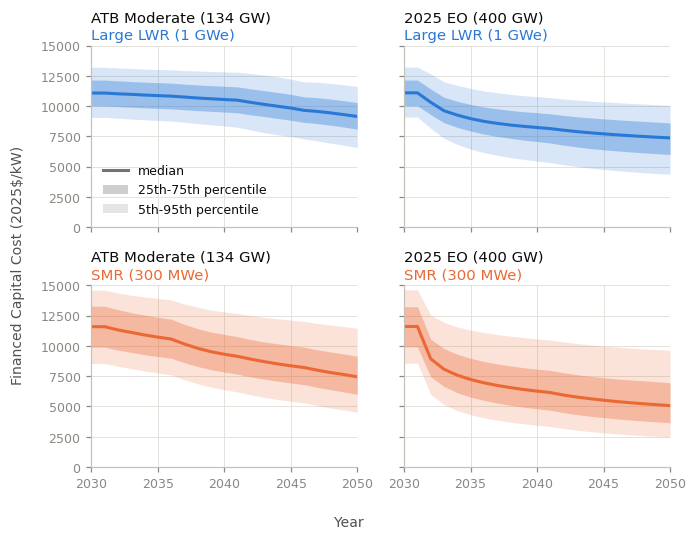

In [16]:
# Financed-capital-cost fans, the source of the paper's Fig 2b: the OCC fans'
# construction, on fincapex = OCC x ccmult(learned duration) x fin_mult_rest (2022 $/kW,
# no ITC; S7) - the cost that carries construction duration and financing. Two
# schedules only (Abou-Jaoude, 2025 EO), one figure per technology, and ONE fixed
# y range shared by all four panels so the two technologies read on the same scale.
# Pre-2030 segment: the plot-only OCC backcast x the draw's own 2025-2029 multiplier
# (results[...]["ccmult"] and FIN_REST cover 2024-2050), so the 2030 splice is exact
# like the OCC fans'. Homogeneous small multiples: not lettered (compose stamps them).
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
PLOT_YEARS = np.concatenate([BACK_YEARS[:-1], YEARS[yi(ANCHOR):]])   # 2025..2050
FIN_FAN_SCHEDS = ["Abou-Jaoude mod", "2025 EO"]
_SHORT_NAME = {"Abou-Jaoude mod": ps.SCHED_SHORT["aj"], "2025 EO": ps.SCHED_SHORT["eo"]}   # paper-facing names (09-10)
assert all(s in SCHED_ORDER for s in FIN_FAN_SCHEDS)
_pre = slice(yi(BACK_YEARS[0]), yi(ANCHOR))                 # 2025..2029 in the YEARS grid
assert YEARS[_pre].tolist() == BACK_YEARS[:-1].tolist()
FIN_FAN_PCT = {}
for tech in TECH:
    for sched in FIN_FAN_SCHEDS:
        r = results[sched][tech]
        mult = r["ccmult"] * FIN_REST[tech][None, :]         # (N_DRAWS, T) financing multiplier
        pre = OCC_BACKCAST[sched][tech][:, :-1] * mult[:, _pre]
        assert np.isfinite(pre).all()
        # splice QA: the backcast's 2030 column x the 2030 multiplier IS the engine's fincapex
        assert np.allclose(OCC_BACKCAST[sched][tech][:, -1] * mult[:, yi(ANCHOR)],
                           r["fincapex"][:, yi(ANCHOR)]), (sched, tech)
        fan_paths = np.concatenate([pre, r["fincapex"][:, yi(ANCHOR):]], axis=1)
        FIN_FAN_PCT[(tech, sched)] = pd.DataFrame(
            {f"P{p}": np.percentile(fan_paths, p, axis=0) for p in (5, 25, 50, 75, 95)},
            index=PLOT_YEARS)
# one y range for all four panels: zero to the next 1,000 above the highest P95
YLIM_FIN = (0.0, float(np.ceil(max(d["P95"].max() for d in FIN_FAN_PCT.values()) / 1000.0) * 1000.0))
# the plotted percentiles (2025-2050, backcast included), for the paper captions
_fin_fan_out = pd.concat({(t, SCEN_TOKEN[s]): d.round(1) for (t, s), d in FIN_FAN_PCT.items()}, axis=1)
_fin_fan_out.to_csv(EXPORTS / "fincapex_fans_aj_eo_percentiles.csv")
print(f"shared y range {YLIM_FIN}; wrote {paths.rel(EXPORTS / 'fincapex_fans_aj_eo_percentiles.csv')}")
for (t, s), d in FIN_FAN_PCT.items():
    print(f"  {t:5s} {s:16s} 2050 P50 {d.loc[2050, 'P50']:8,.0f}  P5-P95 {d.loc[2050, 'P5']:8,.0f}-{d.loc[2050, 'P95']:8,.0f}")
# The figure plots the export as read back from disk (0.1 $/kW), which is how the paper's
# panel was emitted; the read-back table equals the in-memory one to 0.05 $/kW.
_fin_back = pd.read_csv(EXPORTS / "fincapex_fans_aj_eo_percentiles.csv", header=[0, 1, 2], index_col=0)
FIN_FAN_PCT = {(t, s): _fin_back[(t, SCEN_TOKEN[s])] for t in TECH for s in FIN_FAN_SCHEDS}
from matplotlib.ticker import MultipleLocator
GW2050 = {s: float(US_SCHEDULES[s][-1]) for s in FIN_FAN_SCHEDS}
# ---- paper Fig 2b: one 2x2 block, rows = technology, columns = target trajectory ------------
# 2026-09-23 (`_edit_20260923_fig2b.py`, draft-v3 comments C7/C8): the two 1x2 figures become
# one block; two-line panel titles (target trajectory + amount on top, technology beneath in the
# technology's own colour, as in Fig 1); the legend says "median"; the panels start in 2030, so
# the pre-2030 first-of-a-kind backcast and the 2030 anchor marker are gone; 2025 dollars.
X0 = 2030                                        # 09-23 (Ethan C7): no pre-2030 backcast
TO2025 = ps.to2025(2022)                         # 09-23: the paper reports 2025 dollars
# the cell's own _SHORT_NAME maps each schedule key to plotstyle.SCHED_SHORT, which the
# 09-23 pass capitalized ("ATB Moderate", "2025 EO") - Ethan C7.
assert _SHORT_NAME["Abou-Jaoude mod"] == "ATB Moderate", "plotstyle.SCHED_SHORT is not capitalized"
# 09-24 (Ethan E11): one type specification for every main figure, scaled to Fig 2's composed
# canvas so the sizes PRINT at plotstyle.PAPER_FONT.
_PF = ps.fonts(ps.PAPER_CANVAS_IN["fig2"])
_plot = {k: d.loc[X0:] * TO2025 for k, d in FIN_FAN_PCT.items()}
_yrs = _plot[("large", FIN_FAN_SCHEDS[0])].index.to_numpy()
YLIM_2X2 = (0.0, float(np.ceil(max(d["P95"].max() for d in _plot.values()) / 1000.0) * 1000.0))
fig, axes = plt.subplots(2, 2, figsize=(ps.W1, 4.9), sharey=True, sharex=True)
for r, tech in enumerate(["large", "smr"]):
    c = ps.COL[tech]
    for k, sched in enumerate(FIN_FAN_SCHEDS):
        ax = axes[r, k]
        pct = _plot[(tech, sched)]
        ax.fill_between(_yrs, pct["P5"], pct["P95"], alpha=0.18, color=c, lw=0)
        ax.fill_between(_yrs, pct["P25"], pct["P75"], alpha=0.35, color=c, lw=0)
        ax.plot(_yrs, pct["P50"], color=c, lw=2.0)
        # two-line panel label: target trajectory and amount, then the technology in its colour
        ax.set_title(f"{_SHORT_NAME[sched]} ({GW2050[sched]:.0f} GW)",
                     fontsize=_PF["panel_title"], color=ps.INK, loc="left",
                     pad=round(_PF["panel_title"] * 1.62))
        ax.text(0.0, 1.02, ps.TECH_LABEL[tech], transform=ax.transAxes,
                fontsize=_PF["panel_title"], color=c, ha="left", va="bottom")
        ax.set_ylim(*YLIM_2X2)
        ax.set_xlim(X0, 2050)
        ax.xaxis.set_major_locator(MultipleLocator(5))
        ax.tick_params(labelsize=_PF["tick"])    # 09-24: plotstyle.PAPER_FONT (E11)
# one shared legend, neutral grey (the two rows carry two colours), in the empty lower-left
_G = "0.45"
axes[0, 0].legend(handles=[Line2D([], [], color=_G, lw=2.0, label="median"),
                           Patch(facecolor=_G, alpha=0.35, label="25th-75th percentile"),
                           Patch(facecolor=_G, alpha=0.18, label="5th-95th percentile")],
                  fontsize=_PF["legend"], loc="lower left")
fig.supylabel(f"Financed Capital Cost {ps.usd('kW', ps.PAPER_DOLLAR_YEAR)}",
              fontsize=_PF["axis_label"], color=ps.MUTED)
fig.supxlabel("Year", fontsize=_PF["axis_label"], color=ps.MUTED)
fig.tight_layout()
ps.savefig(fig, EXPORTS / "fincapex_fans_2x2.png")
plt.show()

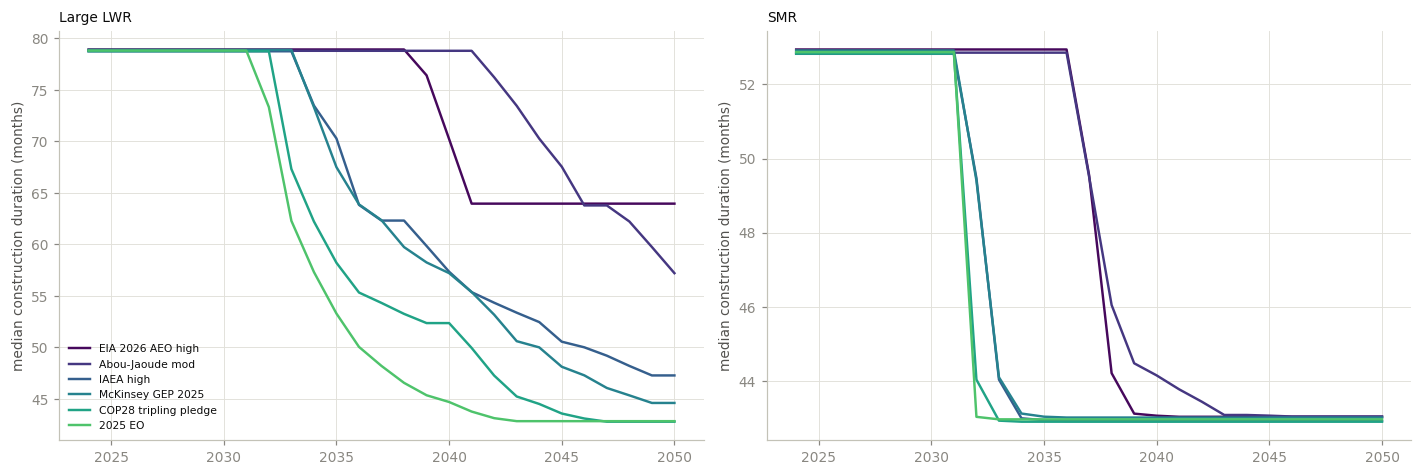

wrote analysis\results\exports\01/mc_{occ,duration,financed_capex}_percentiles_by_schedule.csv


large                                                              \
     eia_aeo_high                                 abou_jaoude                   
               P5     P25     P50     P75     P95          P5     P25     P50   
2030       5380.0  5872.0  6492.0  7121.0  7621.0      5377.0  5872.0  6496.0   
2040       4683.0  5426.0  6028.0  6682.0  7402.0      4933.0  5576.0  6172.0   
2050       4408.0  5274.0  5894.0  6581.0  7349.0      4165.0  5130.0  5739.0   

                      ...     smr                                          \
                      ...   cop28                                  eo2025   
         P75     P95  ...      P5     P25     P50     P75     P95      P5   
2030  7130.0  7623.0  ...  5716.0  6608.0  7728.0  8879.0  9779.0  5733.0   
2040  6822.0  7442.0  ...  2789.0  3810.0  4812.0  6038.0  7676.0  2373.0   
2050  6468.0  7286.0  ...  1891.0  2750.0  3779.0  5067.0  6890.0  1693.0   

                                      
                                      
         P25     P50     P75     P95  
2030  6648.0  7758.0  8864.0  9767.0  
2040  3300.0  4303.0  5536.0  7256.0  
2050  2512.0  3483.0  4780.0  6610.0  

[3 rows x 60 columns]

In [17]:
# Duration fans (medians with P5-P95 band), per schedule - and the percentile-table exports
fig, axes = plt.subplots(1, 2, figsize=(ps.W3, 4.4), sharex=True)
for ax, tech, tlabel in zip(axes, TECH, ["Large LWR", "SMR"]):
    for sched in SCHED_ORDER:
        ax.plot(YEARS, np.percentile(results[sched][tech]["dur"], 50, axis=0), lw=1.6,
                color=SCHED_COLOR[sched], label=sched)
    ax.set_title(tlabel, fontsize=9)
    ax.set_ylabel("median construction duration (months)")
# lower left is the only region clear of every curve (upper right sat on the
# Abou-Jaoude mod plateau)
axes[0].legend(fontsize=7, loc="lower left")
plt.tight_layout()
plt.show()                                     # display only (not a paper item)

# Percentile-table exports (analysis-facing; the ReEDS-facing case exports are in S12)
occ_by_sched = pd.concat({(t, SCEN_TOKEN[s]): percentile_table(results[s][t]["occ"]).round(1)
                          for t in TECH for s in SCHED_ORDER}, axis=1)
dur_by_sched = pd.concat({(t, SCEN_TOKEN[s]): percentile_table(results[s][t]["dur"]).round(1)
                          for t in TECH for s in SCHED_ORDER}, axis=1)
fin_by_sched = pd.concat({(t, SCEN_TOKEN[s]): percentile_table(results[s][t]["fincapex"]).round(1)
                          for t in TECH for s in SCHED_ORDER}, axis=1)
occ_by_sched.to_csv(EXPORTS / "mc_occ_percentiles_by_schedule.csv")
dur_by_sched.to_csv(EXPORTS / "mc_duration_percentiles_by_schedule.csv")
fin_by_sched.to_csv(EXPORTS / "mc_financed_capex_percentiles_by_schedule.csv")
print(f"wrote {paths.rel(EXPORTS)}/mc_{{occ,duration,financed_capex}}_percentiles_by_schedule.csv")
occ_by_sched.loc[[2030, 2040, 2050]].round(0)

saved -> analysis\results\figures\si\SF03_financed_capital_cost_all_trajectories.png


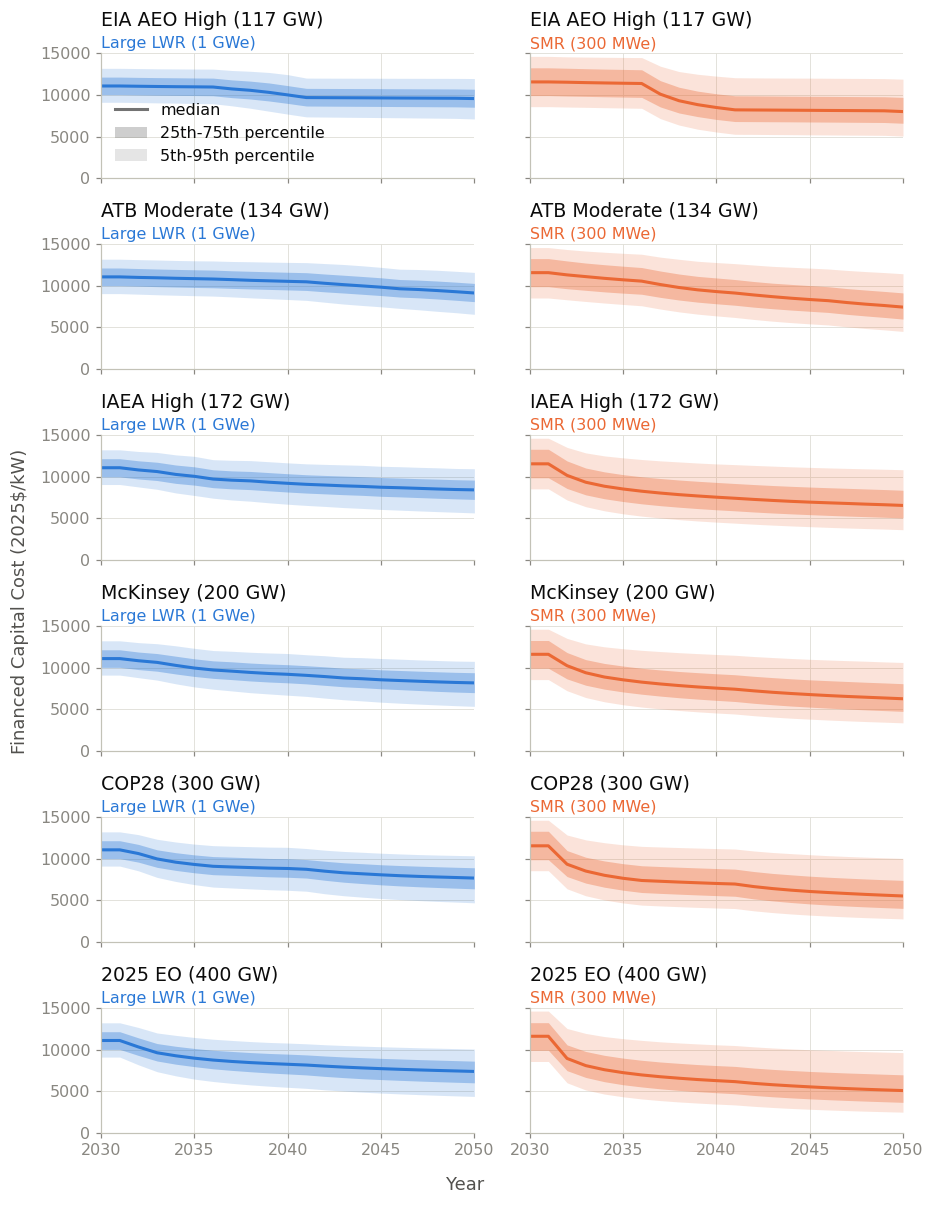

In [18]:
# Supplementary Figure 3: the all-six-target twin of main-text Fig 2b. It plots the percentile
# table the previous cell exported, read back from disk (as the paper's figure was emitted).
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import MultipleLocator
_TOKEN_ALL6 = {"eia": "eia_aeo_high", "aj": "abou_jaoude", "iaea": "iaea_high",
               "mck": "mckinsey", "cop28": "cop28", "eo": "eo2025"}
_fin_all_back = pd.read_csv(EXPORTS / "mc_financed_capex_percentiles_by_schedule.csv",
                            header=[0, 1, 2], index_col=0)
import warnings
with warnings.catch_warnings():               # a 3-level header read back from CSV is not lexsorted
    warnings.simplefilter("ignore", pd.errors.PerformanceWarning)
    FIN_ALL_PCT = {(t, ab): _fin_all_back[(t, _TOKEN_ALL6[ab])]
                   for t in TECH for ab in ps.SCHED_ORDER}
# the six-trajectory table agrees with the Fig 2b export wherever the two overlap (2030-2050)
for t in TECH:
    for ab in ("aj", "eo"):
        assert np.array_equal(FIN_ALL_PCT[(t, ab)].loc[2030:].to_numpy(),
                              _fin_back[(t, _TOKEN_ALL6[ab])].loc[2030:].to_numpy()), (t, ab)
# ---- SI: financed capital cost fans, all six target trajectories, both reactor classes -------
# 2026-09-23 (`_edit_20260923_si_fincapex_all6.py`, Ethan C16 / draft P0044). The SI twin of
# main-text Fig 2b: Fig 2b shows two target trajectories, this shows all six, so the reader can
# see that the other four fall between ATB Moderate and 2025 EO. Rows are target trajectories,
# columns reactor classes, two-line panel titles in the Fig 2b idiom, one shared y axis, x from
# 2030 (no pre-2030 backcast, no demonstration-window marker), money in 2025 dollars.
X0 = 2030
TO2025 = ps.to2025(2022)                         # the export is 2022 $/kW; the paper reports 2025 $
assert ps.SCHED_SHORT["aj"] == "ATB Moderate", "plotstyle.SCHED_SHORT is not capitalized"
_plot = {k: d.loc[X0:] * TO2025 for k, d in FIN_ALL_PCT.items()}
_yrs = _plot[("large", ps.SCHED_ORDER[0])].index.to_numpy()
YLIM_ALL6 = (0.0, float(np.ceil(max(d["P95"].max() for d in _plot.values()) / 1000.0) * 1000.0))
# 09-24 (Ethan E11): one type specification for the whole paper and its SI. The sizes are
# scaled to this canvas, so they PRINT at plotstyle.PAPER_FONT. The canvas is 8.6 in rather
# than 6.5: twelve panels in six rows are taller than the page allows, so at 6.5 in the page
# shrank the figure to 4.96 in wide and its type with it. At 8.6 in the aspect is inside the
# page cap and the figure prints the full 6.5 in wide.
FIGW_SF3 = 8.60           # the canvas this cell asks matplotlib for
CW_SF3 = 8.49             # its width once tight_layout and the tight bbox have trimmed it
_PF3 = ps.fonts(CW_SF3)
fig, axes = plt.subplots(6, 2, figsize=(FIGW_SF3, 11.0), sharey=True, sharex=True)
for r, ab in enumerate(ps.SCHED_ORDER):
    for k, tech in enumerate(TECH):
        ax, c = axes[r, k], ps.COL[tech]
        pct = _plot[(tech, ab)]
        ax.fill_between(_yrs, pct["P5"], pct["P95"], alpha=0.18, color=c, lw=0)
        ax.fill_between(_yrs, pct["P25"], pct["P75"], alpha=0.35, color=c, lw=0)
        ax.plot(_yrs, pct["P50"], color=c, lw=2.0)
        # two-line panel label: target trajectory and its 2050 fleet amount, then the reactor
        # class beneath it in that class's own colour (the Fig 1 / Fig 2b colour)
        ax.set_title(ps.SCHED_LABEL[ab], fontsize=_PF3["panel_title"], color=ps.INK,
                     loc="left", pad=18)
        ax.text(0.0, 1.02, ps.TECH_LABEL[tech], transform=ax.transAxes,
                fontsize=_PF3["annotation"],
                color=c, ha="left", va="bottom")
        ax.set_ylim(*YLIM_ALL6)
        ax.set_xlim(X0, 2050)
        ax.xaxis.set_major_locator(MultipleLocator(5))
        ax.tick_params(labelsize=_PF3["tick"])
# one shared legend, neutral grey (the two columns carry two colours)
_G = "0.45"
axes[0, 0].legend(handles=[Line2D([], [], color=_G, lw=2.0, label="median"),
                           Patch(facecolor=_G, alpha=0.35, label="25th-75th percentile"),
                           Patch(facecolor=_G, alpha=0.18, label="5th-95th percentile")],
                  fontsize=_PF3["legend"], loc="lower left")
fig.supylabel(f"Financed Capital Cost {ps.usd('kW', ps.PAPER_DOLLAR_YEAR)}",
              fontsize=_PF3["axis_label"], color=ps.MUTED)
fig.supxlabel("Year", fontsize=_PF3["axis_label"], color=ps.MUTED)
fig.tight_layout()
ps.savefig(fig, FIGS_SI / "SF03_financed_capital_cost_all_trajectories.png")
plt.show()

## 9 · Technology ranking, the per-draw export, and the ST1 check

For each draw, the cell below scores each reactor class by its *program cost*: the discounted,
capacity-weighted total financed cost of the schedule's builds,
R_d = Σ_t ΔK(t) · fincapex_d(t) / d̄^(t−2030), where ΔK(t) is the schedule's gross capacity additions
and d̄ is ReEDS's real discount rate. The cheaper class "wins" the draw. The win shares per schedule
are a quoted result (`win_probabilities.csv`). Notebook 04 selects the ReEDS cases (the 100%-SMR
program) from this per-draw file; this notebook selects none.

The per-draw export `mc_perdraw.npz` keeps what the percentile tables discard: the drawn parameters
(`worlds_<tok>`, columns in `world_columns`), the program-cost scores under three ranking
functionals (`R_`, `R_undiscounted_`, `R_unweighted_`), the winners, the capacity additions, the
discount factors, and the full-channel `occ`, `dur`, `ccmult` and `fincapex` arrays (2022 $/kW,
no ITC) for every schedule and reactor class. When the ReEDS output archive is present
(`NL_REEDS_OUTPUTS`), the cell also places a copy there, because the file is too large for git.

The ST1 check then verifies every stated support of Supplementary Table 1 against the 60,000 saved
worlds. The last cell reports how often the winner changes under the two alternative ranking
functionals (`winner_ranking_invariance.csv`) and asserts that the loser channel is never cheaper
than the full channel.

In [19]:
# Schedule capacity-addition weights and discount factors for the ranking functional
GW_ADDITIONS = {s: np.diff(USN_NEW["large"][s], prepend=0.0) * TECH["large"]["unit_gw"]
                for s in SCHED_ORDER}          # gross GW added per year (tech-independent)
DISC = np.cumprod(np.where(YEARS > ANCHOR, FIN["d_real"], 1.0))   # discount to 2030

def rank_draws(sched, tech, channel="fincapex", functional=None):
    """Program-cost score per draw (lower = cheaper program), for the given schedule/tech.

    functional: "discounted_schedule_weighted" (DEFAULT - paper plan issue 8),
                "unweighted" (plain time average), "undiscounted" (weights, no discounting).
    """
    functional = RANKING_FUNCTIONAL if functional is None else functional
    fc = results[sched][tech][channel]
    if functional == "unweighted":
        return fc.mean(axis=1)
    w = GW_ADDITIONS[sched] / (DISC if functional == "discounted_schedule_weighted" else 1.0)
    return fc @ w

WINNERS = {}         # WINNERS[sched] -> array of "large"/"smr" per draw
for sched in SCHED_ORDER:
    r_large = rank_draws(sched, "large")
    r_smr = rank_draws(sched, "smr")
    WINNERS[sched] = np.where(r_large <= r_smr, "large", "smr")

win_tab = pd.DataFrame({s: {"P(large wins)": (WINNERS[s] == "large").mean(),
                            "P(smr wins)": (WINNERS[s] == "smr").mean()}
                        for s in SCHED_ORDER}).T.round(3)
print("Win probabilities per schedule (a paper table, and regroup evidence for issue 8):")
print(win_tab.to_string())
win_tab.to_csv(EXPORTS / "win_probabilities.csv")

Win probabilities per schedule (a paper table, and regroup evidence for issue 8):
                       P(large wins)  P(smr wins)
EIA 2026 AEO high              0.181        0.819
Abou-Jaoude mod                0.146        0.854
IAEA high                      0.137        0.863
McKinsey GEP 2025              0.133        0.867
COP28 tripling pledge          0.122        0.878
2025 EO                        0.114        0.886


In [20]:
# Per-draw export (winner_boundary.ipynb): everything the percentile CSVs discard.
# Full channel only - the winner comparison puts both techs at the whole program;
# the loser _intl channels are not needed downstream.
perdraw = {
    "world_columns": np.array(WORLDS[SCHED_ORDER[0]].columns, dtype=str),
    "years": YEARS,
    "disc": DISC,
    "sched_order": np.array(SCHED_ORDER, dtype=str),
    "scen_tokens": np.array([SCEN_TOKEN[s] for s in SCHED_ORDER], dtype=str),
    "meta_json": np.array(json.dumps({
        "master_seed": MASTER_SEED, "n_draws": N_DRAWS,
        "ranking_functional_default": RANKING_FUNCTIONAL,
        "copula_set": COPULA_SET, "use_itc_in_ranking": USE_ITC_IN_RANKING,
        "fincapex_definition": "OCC x ccmult(learned duration) x fin_mult_rest; 2022 $/kW, noITC",
        "channel": "full (tech gets the whole program); loser _intl channels not exported",
    })),
}
for sched in SCHED_ORDER:
    tok = SCEN_TOKEN[sched]
    perdraw[f"worlds_{tok}"] = WORLDS[sched].to_numpy(dtype=float)
    perdraw[f"winners_{tok}"] = WINNERS[sched]
    perdraw[f"gw_additions_{tok}"] = GW_ADDITIONS[sched]
    for tech in TECH:
        for functional in ("discounted_schedule_weighted", "undiscounted", "unweighted"):
            key = "R" if functional == RANKING_FUNCTIONAL else f"R_{functional}"
            perdraw[f"{key}_{tok}_{tech}"] = rank_draws(sched, tech, functional=functional)
        for ch in ("occ", "dur", "ccmult", "fincapex"):
            perdraw[f"{ch}_{tok}_{tech}"] = results[sched][tech][ch]

np.savez_compressed(EXPORTS / "mc_perdraw.npz", **perdraw)
sz = (EXPORTS / "mc_perdraw.npz").stat().st_size / 1e6
print(f"wrote {paths.rel(EXPORTS / 'mc_perdraw.npz')} ({sz:,.0f} MB, {len(perdraw)} arrays): "
      f"{len(SCHED_ORDER)} schedules x (worlds, winners, gw_additions, "
      f"3 rank-score functionals x 2 techs, 4 trajectory arrays x 2 techs)")

# The npz is git-ignored; the ReEDS output archive ships it. When the archive is present, copy
# the file there unless the archive already holds an array-identical copy.
_arch = paths.reeds_outputs(quiet=True)
if _arch is None:
    print("output archive not found (NL_REEDS_OUTPUTS unset): archive copy skipped")
else:
    _dst = _arch / "mc_perdraw.npz"
    _same = False
    if _dst.exists():
        with np.load(_dst) as _a, np.load(EXPORTS / "mc_perdraw.npz") as _b:
            _same = set(_a.files) == set(_b.files) and all(np.array_equal(_a[k], _b[k]) for k in _b.files)
    if _same:
        print("archive copy is current: <NL_REEDS_OUTPUTS>/mc_perdraw.npz")
    else:
        shutil.copy2(EXPORTS / "mc_perdraw.npz", _dst)
        print("copied mc_perdraw.npz into the output archive: <NL_REEDS_OUTPUTS>/mc_perdraw.npz")

wrote analysis\results\exports\01\mc_perdraw.npz (50 MB, 108 arrays): 6 schedules x (worlds, winners, gw_additions, 3 rank-score functionals x 2 techs, 4 trajectory arrays x 2 techs)


archive copy is current: <NL_REEDS_OUTPUTS>/mc_perdraw.npz


In [21]:
# ST1 check: every stated support in Supplementary Table 1 against the saved draws.
Z = np.load(EXPORTS / "mc_perdraw.npz")
meta = json.loads(str(Z["meta_json"]))
assert meta["n_draws"] == 10000 and meta["copula_set"] == "moderate"
assert meta["master_seed"] == 20260715
cols = [str(c) for c in Z["world_columns"]]
w_all = pd.DataFrame(np.vstack([Z[f"worlds_{str(t)}"] for t in Z["scen_tokens"]]), columns=cols)
BOUNDS = {"lr_large": (0.03, 0.12), "lr_smr": (0.03, 0.16),
          "boak_large": (5250.0, 7750.0), "boak_smr": (5500.0, 10000.0),
          "u": (0.0, 1.0), "s": (0.0, 1.0),
          "x_ls": (0.0, 0.30), "x_sl": (0.0, 0.30),
          "dur_lambda": (0.0, 1.0)}
for col, (lo, hi) in BOUNDS.items():
    v = w_all[col]
    assert v.min() >= lo - 1e-12 and v.max() <= hi + 1e-12, col
    assert (v.max() - v.min()) >= 0.999 * (hi - lo), col  # draws fill the range
assert set(w_all["n_vendors"].astype(int)) == {4, 5, 6, 7, 8}
assert set(w_all["conv_full"].astype(int)) == {0, 1}
assert set(np.round(w_all["ces_rho"], 6)) == {-1.0, 0.0, 1.0}
# comonotone pairs: one latent sets both classes (rank correlation 1)
assert np.isclose(stats.spearmanr(w_all["lr_large"], w_all["lr_smr"]).statistic, 1.0)
assert np.isclose(stats.spearmanr(w_all["boak_large"], w_all["boak_smr"]).statistic, 1.0)
Z.close()
print(f"ST1 supports verified against {len(w_all):,} drawn worlds in mc_perdraw.npz "
      "(ranges filled, discrete sets complete, learning rates and anchor costs comonotone)")

ST1 supports verified against 60,000 drawn worlds in mc_perdraw.npz (ranges filled, discrete sets complete, learning rates and anchor costs comonotone)


In [22]:
# QA12 - loser-channel sanity + winner robustness (report - regroup evidence for issue 8)
# (a) the international-only path can never be cheaper than the full path (less learning)
for sched in SCHED_ORDER:
    for tech in TECH:
        gap = results[sched][tech]["occ_intl"] - results[sched][tech]["occ"]
        assert gap.min() > -1e-6, (sched, tech, gap.min())
print("QA12 (a) PASSED: occ_intl >= occ elementwise, every draw/schedule/tech "
      "(the loser is never cheaper than the winner-path of the same tech)")
# (b) winner invariance under the ranking-functional choice - reported, not asserted
rows = {}
for sched in SCHED_ORDER:
    base = WINNERS[sched]
    for alt in ("unweighted", "undiscounted"):
        wa = np.where(rank_draws(sched, "large", functional=alt)
                      <= rank_draws(sched, "smr", functional=alt), "large", "smr")
        rows[(sched, alt)] = {"winner match vs default": (wa == base).mean()}
inv = pd.DataFrame(rows).T
print("QA12 (b) report - winner agreement between ranking functionals (issue 8 evidence):")
print(inv.round(3).to_string())
inv.to_csv(EXPORTS / "winner_ranking_invariance.csv")

QA12 (a) PASSED: occ_intl >= occ elementwise, every draw/schedule/tech (the loser is never cheaper than the winner-path of the same tech)
QA12 (b) report - winner agreement between ranking functionals (issue 8 evidence):
                                    winner match vs default
EIA 2026 AEO high     unweighted                      0.886
                      undiscounted                    0.986
Abou-Jaoude mod       unweighted                      0.866
                      undiscounted                    0.987
IAEA high             unweighted                      0.938
                      undiscounted                    0.989
McKinsey GEP 2025     unweighted                      0.931
                      undiscounted                    0.992
COP28 tripling pledge unweighted                      0.940
                      undiscounted                    0.993
2025 EO               unweighted                      0.946
                      undiscounted                    0.994

## 10 · Fragmentation: what splitting the program costs (SF5 panel f)

Winner-take-all assignment assumes that concentrating the build program on one reactor class beats
splitting it. This cell prices the split for the 200-GW McKinsey schedule. For each draw it computes
the discounted financed cost of the program three ways (all large, all SMR, 50/50) in the same
drawn world, with each half of the split cross-teaching the other through the drawn x. The
*fragmentation penalty* is the split program's cost over the cheaper concentrated program, minus 1.

The standalone histogram `fragmentation_hist.png` is panel f of Supplementary Figure 5 (notebook
16 composes the page with notebook 03a's mixed-build panels). Its baked letter "f" and axis labels
are kept exactly as the paper shows them. The two-panel companion figure is displayed only.

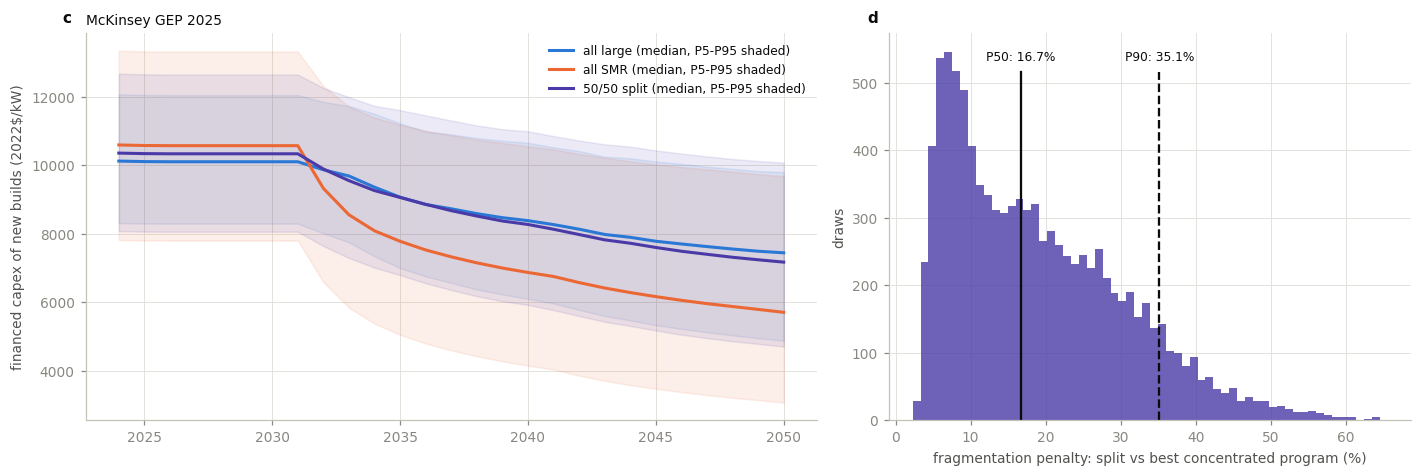

saved -> analysis\results\exports\01\fragmentation_hist.png


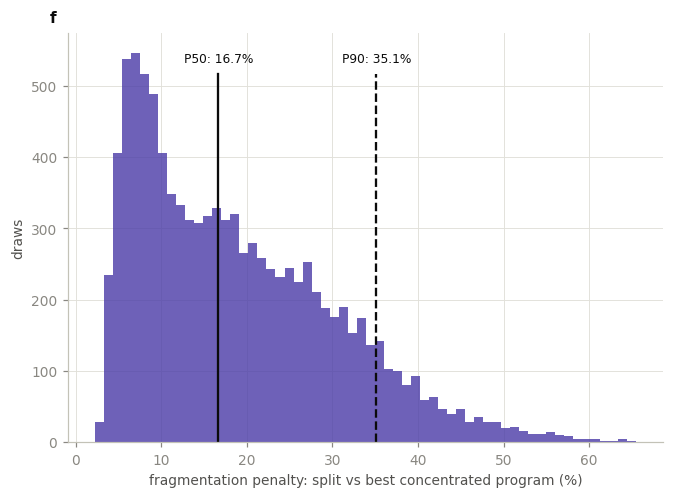

fragmentation penalty (McKinsey GEP 2025, drawn cross-tech spillover x~U(0, 0.3)): median 16.7%, P90 35.1%, negative in 0.0% of draws


In [23]:
# Fragmentation arms for the representative schedule (switchable)
FRAG_SCHED = "McKinsey GEP 2025"
_w = WORLDS[FRAG_SCHED]
_gw_add = GW_ADDITIONS[FRAG_SCHED]                      # gross GW added per year

def program_cost_paths(occ_by_tech, fincapex_by_tech, shares):
    """Capacity-weighted average financed CAPEX of the build program, per draw-year.
    shares: {tech: fraction of each year's additions} summing to 1."""
    return sum(shares[t] * fincapex_by_tech[t] for t in shares)

# Concentrated arms are the S8 full channels; the split arm re-runs the engine with each
# tech receiving HALF the program (same worlds - so the comparison is like for like)
frag = {}
frag["all large"] = {"fincapex": results[FRAG_SCHED]["large"]["fincapex"]}
frag["all SMR"] = {"fincapex": results[FRAG_SCHED]["smr"]["fincapex"]}
split_fc = {}
for tech in TECH:
    n_half = USN_NEW[tech][FRAG_SCHED] / 2.0            # half the capacity -> half the units
    n_half_oth = USN_NEW[OTHER_TECH[tech]][FRAG_SCHED] / 2.0
    occ_h = occ_paths_ces(_w, tech, n_half, n_oth=n_half_oth)   # each half cross-teaches the other
    dur_h = duration_paths(_w, tech, n_half)
    split_fc[tech] = occ_h * ccmult_grid(dur_h, tech) * FIN_REST[tech][None, :]
frag["50/50 split"] = {"fincapex": 0.5*split_fc["large"] + 0.5*split_fc["smr"]}

# Program totals under the default ranking functional, and the per-draw penalty
w_t = _gw_add / DISC
R = {arm: frag[arm]["fincapex"] @ w_t for arm in frag}
best_conc = np.minimum(R["all large"], R["all SMR"])
penalty = R["50/50 split"] / best_conc - 1.0

fig, axes = plt.subplots(1, 2, figsize=(ps.W3, 4.4), width_ratios=[1.4, 1])
ax = axes[0]
# Concentrated arms wear their tech colors; the split arm is a mix of both, so it
# gets a one-off accent distinct from either tech hue.
colors = {"all large": ps.COL["large"], "all SMR": ps.COL["smr"],
          "50/50 split": ps.ACCENT["violet"]}
for arm, col in colors.items():
    pct = percentile_table(frag[arm]["fincapex"])
    ax.fill_between(YEARS, pct["P5"], pct["P95"], alpha=0.10, color=col)
    ax.plot(YEARS, pct["P50"], color=col, lw=2, label=f"{arm} (median, P5-P95 shaded)")
ax.set_ylabel(f"financed capex of new builds {ps.usd('kW', 2022)}")
ax.set_title(FRAG_SCHED, fontsize=9)
ax.legend(fontsize=8)
ax = axes[1]
ax.hist(100*penalty, bins=60, color=ps.ACCENT["violet"], alpha=0.8)
for q, ls in [(50, "-"), (90, "--")]:
    v = np.percentile(100*penalty, q)
    ax.plot([v, v], [0, ax.get_ylim()[1]*0.9], color=ps.INK, ls=ls, lw=1.5)
    ax.text(v, ax.get_ylim()[1]*0.93, f"P{q}: {v:.1f}%", ha="center", fontsize=8)
ax.set_xlabel("fragmentation penalty: split vs best concentrated program (%)")
ax.set_ylabel("draws")
# The two-panel figure keeps letters c/d as a notebook-record artifact (it left
# the composed paper figure in the 2026-08-26 Fig 3 recomposition); the paper
# panel was the standalone histogram below (baked "b" until 2026-08-31); it now
# lives in the SI mixing page SF6 as panel f.
ps.panel_letter(axes[0], "c")
ps.panel_letter(axes[1], "d")
plt.tight_layout()
plt.show()                                     # display only (not a paper item)

# SI figure SF6 panel f (was paper Fig 3b, 2026-08-26 to 2026-08-31): the penalty
# histogram standalone. The third Fig 3 recomposition gave panel b to the baseline
# value-of-waiting panel (EVPI + 2036 switch bound vs kappa) and re-homed this
# histogram on the SI mixing page next to the mixed-build optimizer maps.
fig2, ax2 = plt.subplots(figsize=(6.2, 4.6))
ax2.hist(100*penalty, bins=60, color=ps.ACCENT["violet"], alpha=0.8)
for q, ls in [(50, "-"), (90, "--")]:
    v = np.percentile(100*penalty, q)
    ax2.plot([v, v], [0, ax2.get_ylim()[1]*0.9], color=ps.INK, ls=ls, lw=1.5)
    ax2.text(v, ax2.get_ylim()[1]*0.93, f"P{q}: {v:.1f}%", ha="center", fontsize=8)
ax2.set_xlabel("fragmentation penalty: split vs best concentrated program (%)")
ax2.set_ylabel("draws")
ps.panel_letter(ax2, "f")
fig2.tight_layout()
ps.savefig(fig2, EXPORTS / "fragmentation_hist.png")
plt.show()
print(f"fragmentation penalty ({FRAG_SCHED}, drawn cross-tech spillover x~U(0, {X_SPILL_MAX})): "
      f"median {np.percentile(100*penalty,50):.1f}%, P90 {np.percentile(100*penalty,90):.1f}%, "
      f"negative in {100*(penalty < 0).mean():.1f}% of draws")

## 11 · Routing sensitivity: foreign units in the own stock

The engine places θ·s-weighted foreign units in the cross-firm stock, because the Kim & Verdolini
citation flows are measured relative to domestic inter-firm flows (ω prices the firm wall, θ the
border). Patent citations cannot see licensing-scale transfer, which was nuclear's main historical
international channel (Westinghouse to France, Combustion Engineering to Korea). This cell therefore
re-prices the McKinsey schedule with foreign units routed into the *own* stock at the full learning
rate, as a deliberate structural upper bound. The variant lives only in this cell; the engine has
one path. Notebook 03b reads `routing_sensitivity.csv`.

In [24]:
# Routing sensitivity (structural, SELF-CONTAINED - not an engine path): re-price one
# schedule with theta*s-weighted foreign units routed into the OWN stock at full LR.
# The production engine keeps them in the cross-firm stock because the K&V flows are
# normalized to the domestic inter-firm citation baseline (S5 Step 5) - the own-channel
# variant over-credits foreign learning by ~1/omega = 3x at the margin relative to what
# K&V measure. It is kept as a deliberate structural UPPER BOUND: patent citations cannot
# see licensing-scale transfer (K&V ignore jointly-filed patents and flag nuclear as
# uncovered by their technology classes), and licensing was nuclear's dominant historical
# international channel (Westinghouse->France, Combustion Engineering->Korea). Everything
# below is local to this cell: tech-split foreign stocks (IAEA SMR share, S3) and a local
# engine variant - the engine itself has exactly one path.
_RS_SPLIT = {"large": {}, "smr": {}}
for _r in REGIONS:
    _ml = np.empty((len(U_GRID), T))
    _ms = np.empty((len(U_GRID), T))
    for _gi, _u in enumerate(U_GRID):
        _g = gross_additions_gw(_r, _u)
        _f = smr_frac(_u)
        _ml[_gi] = post_anchor_cum(_g*(1.0 - _f)) / UNIT_FOREIGN_GW
        _ms[_gi] = post_anchor_cum(_g*_f) / TECH["smr"]["unit_gw"]
    _RS_SPLIT["large"][_r], _RS_SPLIT["smr"][_r] = _ml, _ms

def _occ_ces_own_routing(world, tech, n_us, n_oth=None):
    """SENSITIVITY ONLY. Own-channel routing: same-tech theta*s foreign units in O at full
    LR (tech-split stocks), cross-tech foreign at x*s in A, plus x * the other technology's
    US program. CES aggregation identical to occ_paths_ces (D11/D12)."""
    n = len(world)
    u_r = np.repeat(world["u"].values[:, None], len(REGIONS), axis=1)
    gi = np.clip(np.rint(u_r * (len(U_GRID)-1)).astype(int), 0, len(U_GRID)-1)
    def _skv(key):
        S = np.zeros((n, T))
        for j, r in enumerate(REGIONS):
            S += THETA_KV[r] * _RS_SPLIT[key][r][gi[:, j], :]
        return lag1(S)
    N_us = lag1(np.broadcast_to(np.asarray(n_us, float), (n, T)))
    conv = world["conv_full"].values[:, None].astype(float)
    m = world["n_vendors"].values[:, None].astype(float)
    s = world["s"].values[:, None]
    x = world[X_IN_COL[tech]].values[:, None]
    hist_us = HIST_UNITS["US"] if tech == "large" else 0.0
    own0 = N_BOAK_UNITS + conv*hist_us/m
    H_same = conv*H_ALL_W if tech == "large" else 0.0     # historical foreign fleet: all large
    H_cross = conv*H_ALL_W if tech == "smr" else 0.0
    own = own0 + N_us/m + s*(H_same + _skv(tech))
    oth = (m-1.0)*own0 + N_us*(m-1.0)/m + x*s*(H_cross + _skv(OTHER_TECH[tech]))
    if n_oth is not None:
        oth = oth + x*lag1(np.broadcast_to(np.asarray(n_oth, float), (n, T)))
    lr = world[f"lr_{tech}"].values[:, None]
    b1, b2 = np.log2(1.0 - lr), np.log2(1.0 - OMEGA*lr)
    b, w = -(b1 + b2), b1/(b1 + b2)
    rho = world["ces_rho"].values[:, None]
    geo = np.abs(rho) < CES_EPS
    lnO, lnA = np.log(own), np.log(oth)
    lnE = np.where(geo, w*lnO + (1.0-w)*lnA,
                   lnO + np.log1p((1.0-w)*np.expm1(np.where(geo, 0.0, rho)*(lnA - lnO)))
                       / np.where(geo, 1.0, rho))
    return world[f"boak_{tech}"].values[:, None] * np.exp(-b*(lnE - lnE[:, [yi(ANCHOR)]]))

route_rows = {}
for label, fn in (("cross_firm (engine)", occ_paths_ces),
                  ("own (upper bound)", _occ_ces_own_routing)):
    for tech in TECH:
        full = fn(WORLDS[FRAG_SCHED], tech, USN_NEW[tech][FRAG_SCHED])[:, yi(2050)]
        loser = fn(WORLDS[FRAG_SCHED], tech, ZEROS_T,
                   n_oth=USN_NEW[OTHER_TECH[tech]][FRAG_SCHED])[:, yi(2050)]
        route_rows[(label, tech)] = {
            "P5": np.percentile(full, 5), "P50": np.percentile(full, 50),
            "P95": np.percentile(full, 95), "loser P50": np.percentile(loser, 50)}
route_tab = pd.DataFrame(route_rows).T.round(0)
print(f"2050 OCC, engine vs the own-routing upper bound ($/kW 2022, {FRAG_SCHED}):")
print(route_tab.to_string())
print("'cross_firm' = the production engine (derivation Step 5: omega prices the firm wall, theta the"
      " border); 'own' = the sensitivity-only upper bound for citation-invisible licensing-scale transfer.")
route_tab.to_csv(EXPORTS / "routing_sensitivity.csv")

2050 OCC, engine vs the own-routing upper bound ($/kW 2022, McKinsey GEP 2025):
                               P5     P50     P95  loser P50
cross_firm (engine) large  3525.0  5378.0  7065.0     6156.0
                    smr    2304.0  4291.0  7277.0     7216.0
own (upper bound)   large  3154.0  5284.0  7075.0     5557.0
                    smr    2160.0  4030.0  7047.0     5794.0
'cross_firm' = the production engine (derivation Step 5: omega prices the firm wall, theta the border); 'own' = the sensitivity-only upper bound for citation-invisible licensing-scale transfer.


## 12 · Regression and QA suite

Each check either asserts (a failure stops the notebook) or prints a report where a pass/fail
reading would be wrong. If any cell here raises, do not trust the outputs above.

| # | Check | Kind |
|---|---|---|
| QA1 | PRIS data reproduce the IAEA's published totals | assert (Section 2) |
| QA2 | Every draw hits its BOAK anchor exactly at 2030, both channels | assert |
| QA3 | At autarky and tiny base, the engine reduces exactly to Abou-Jaoude's eq. (12) | assert |
| QA4 | The engine's eq. (12) reproduces Abou-Jaoude's published SMR cost tables (cited in SN1) | assert |
| QA4b | Same for the large-reactor tables, at the report's industry-unit attachment | assert |
| QA5 | Hindcast: where Korea, France and US history fall in the sampled learning-rate range | report (`hindcast_positions.csv`) |
| QA6 | CES suite: anchor invariance, ρ→0 limit, autarky collapse, continuity, direction | assert + report |
| QA8 | Duration anchors (series-2 base, SMR floor) match the ReEDS engine's self-test | assert |
| QA9 | CCmult regression value (Section 6) | assert |
| QA12 | Loser channel never cheaper; winner invariance (Section 9) | assert + report |
| QA13 | The six ensembles draw statistically identical worlds | assert |

QA5 compares on the *effective industry learning rate* 1 − (1 − LR)(1 − ω·LR) ≈ 1.3·LR, because the
observed national rates are industry-level while the sampled LR is firm-level. The hindcast
histogram is displayed only.

In [25]:
# QA2 - anchor check: OCC(2030) == the drawn BOAK, every draw, both channels, all schedules
for sched in SCHED_ORDER:
    for tech in TECH:
        boak = WORLDS[sched][f"boak_{tech}"].values
        assert np.allclose(results[sched][tech]["occ"][:, yi(ANCHOR)], boak), (sched, tech)
        assert np.allclose(results[sched][tech]["occ_intl"][:, yi(ANCHOR)], boak), (sched, tech)
print("QA2 PASSED: every draw hits its BOAK anchor exactly at 2030 "
      "(all schedules, both techs, full and international-only channels)")

QA2 PASSED: every draw hits its BOAK anchor exactly at 2030 (all schedules, both techs, full and international-only channels)


In [26]:
# QA3 - eq.(12) identity: at s = 0 (autarky), tiny base, the sigma = 1 engine must equal
# Abou-Jaoude's eq. (12) generalized to m vendors and re-anchored at the per-vendor 2OAK point.
wtest = draw_world(4, "zero", rng_stream("qa3"))
wtest[["s", "conv_full", "x_ls", "x_sl"]] = 0.0    # autarky: no intl, no cross-tech

def eq12_gen(N, LR, m):
    return (1-LR)**np.log2(N/m) * (1-OMEGA*LR)**np.log2((m-1)*N/m)

_sched_test = "2025 EO"   # the most builds -> the strongest test
N_us_test = lag1(np.broadcast_to(USN_NEW["large"][_sched_test], (4, T)))  # engine prices lagged stock
N_ind = wtest["n_vendors"].values[:, None]*N_BOAK_UNITS + N_us_test
analytic = wtest["boak_large"].values[:, None] * (
    eq12_gen(N_ind, wtest["lr_large"].values[:, None], wtest["n_vendors"].values[:, None])
    / eq12_gen(wtest["n_vendors"].values[:, None]*N_BOAK_UNITS,
               wtest["lr_large"].values[:, None], wtest["n_vendors"].values[:, None]))
assert np.allclose(occ_paths(wtest, "large", USN_NEW["large"][_sched_test]), analytic)
print("QA3 PASSED: engine reduces exactly to generalized eq.(12), per-vendor anchored "
      f"(tested on the '{_sched_test}' schedule)")

QA3 PASSED: engine reduces exactly to generalized eq.(12), per-vendor anchored (tested on the '2025 EO' schedule)


In [27]:
# QA4 - external anchor: reproduce Abou-Jaoude's published SMR OCC tables (Tables 50/52/54)
# with his own eq. (12) under his deployment assumptions (4 vendors, LR 9.5%), within the
# report's rounding. This pins the code to the published source it claims to implement.
AJ_DEPLOY_GW = {"Conservative": {2030: 0, 2035: 1, 2040: 3, 2045: 6, 2050: 12},
                "Moderate":     {2030: 1, 2035: 3, 2040: 8.5, 2045: 17, 2050: 34},
                "Advanced":     {2030: 1, 2035: 14, 2040: 58, 2045: 124, 2050: 200}}
AJ_OCC_SMR = {"Conservative": {2030: 10000, 2035: 9500, 2040: 8000, 2045: 7000, 2050: 6250},
              "Moderate":     {2030: 8000, 2035: 6500, 2040: 5250, 2045: 4500, 2050: 4000},
              "Advanced":     {2030: 5500, 2035: 3250, 2040: 2500, 2045: 2250, 2050: 2000}}
AJ_BOAK = {"Conservative": 10000.0, "Moderate": 8000.0, "Advanced": 5500.0}

def eq12_factor(N, LR):
    N = np.asarray(N, float)
    with np.errstate(divide="ignore", invalid="ignore"):
        return (1/(1-LR)) * (1-LR)**np.log2(N/4) * (1-LR/3)**np.log2(3*N/4)

worst = 0.0
for name in AJ_BOAK:
    yrs = sorted(AJ_DEPLOY_GW[name])
    gw = np.array([AJ_DEPLOY_GW[name][y] for y in yrs], float)
    N = gw / 0.3
    fref = eq12_factor(1.0/0.3, 0.095)
    mult = np.minimum(1.0, np.where(N > 0, eq12_factor(N, 0.095)/fref, 1.0))
    err = np.abs(AJ_BOAK[name]*mult - np.array([AJ_OCC_SMR[name][y] for y in yrs], float)).max()
    worst = max(worst, err)
# NOTE (2026-08-24): worst lands on $500 exactly via ONE structural artifact, not rounding:
# fref is pinned at 1 GW for all three scenarios while Conservative has 0 GW in 2030, so
# the N > 0 branch forces mult = 1 at 2030/2035; every other year's error is <= $164.
assert worst <= 500.0, worst
print(f"QA4 PASSED: Abou-Jaoude SMR tables reproduced, max error ${worst:,.0f}/kW "
      "(within report rounding)")

QA4 PASSED: Abou-Jaoude SMR tables reproduced, max error $500/kW (within report rounding)


In [28]:
# QA4b - published-source pin, large-reactor half: reproduce Abou-Jaoude's large OCC
# tables (Tables 50/52/54) with his eq. (12) at LR 8%, m = 4, 1 GW units. The large
# columns attach the learning index at Nref = 2 INDUSTRY units (report eq. (10)
# "BOAK = 2OAK" with N counted industry-wide = 0.5 units/firm), NOT at the first 1 GW
# used by the SMR columns (3.33 units = 0.83/firm): back-solve best fit N = 1.96,
# $50-band [1.87, 2.22]; Nref = 2 max error $271 vs $994 for the first-GW reading.
# Our engine reads the same "BOAK = 2OAK" phrase PER VENDOR (own0 = 2/firm = 8 industry
# units at m = 4) - the three-way fork the anchor-convention memo puts to Abou-Jaoude.
# (Report-side note: Table 53's advanced large/SMR decline columns are swapped relative
# to Table 54's OCC values; replication targets the OCC tables, so QA is unaffected.)
AJ_OCC_LGE = {"Conservative": {2030: 7750, 2035: 7750, 2040: 7500, 2045: 6750, 2050: 6000},
              "Moderate":     {2030: 5750, 2035: 5500, 2040: 4750, 2045: 4250, 2050: 3750},
              "Advanced":     {2030: 5250, 2035: 4000, 2040: 3000, 2045: 2500, 2050: 2250}}
AJ_BOAK_LGE = {"Conservative": 7750.0, "Moderate": 5750.0, "Advanced": 5250.0}

worst_lge, worst_1gw = 0.0, 0.0
for name in AJ_BOAK_LGE:
    yrs = sorted(AJ_DEPLOY_GW[name])
    N = np.array([AJ_DEPLOY_GW[name][y] for y in yrs], float) / 1.0   # 1 GW per unit
    tab = np.array([AJ_OCC_LGE[name][y] for y in yrs], float)
    for nref, tracker in ((2.0, "lge"), (1.0, "1gw")):
        mult = np.minimum(1.0, np.where(N > 0,
                                        eq12_factor(N, 0.08)/eq12_factor(nref, 0.08), 1.0))
        err = np.abs(AJ_BOAK_LGE[name]*mult - tab).max()
        if tracker == "lge":
            worst_lge = max(worst_lge, err)
        else:
            worst_1gw = max(worst_1gw, err)
assert worst_lge <= 300.0, worst_lge          # $250 table rounding + fit slack
assert worst_1gw >= 900.0, worst_1gw          # the SMR-style first-GW reading is rejected
print(f"QA4b PASSED: Abou-Jaoude LARGE tables reproduced at Nref = 2 industry units, "
      f"max error ${worst_lge:,.0f}/kW (first-1-GW reading fails at ${worst_1gw:,.0f}/kW)")

QA4b PASSED: Abou-Jaoude LARGE tables reproduced at Nref = 2 industry units, max error $271/kW (first-1-GW reading fails at $994/kW)


sampled firm-level LR (large) implies an effective industry rate: P5=4.6%  P50=9.9%  P95=15.0%
  Korea 1972-2008 (Lovering et al. 2016): LR ~ +13% -> P77 of the sampled range
  France 1970s-1990s (Grubler 2010): LR ~ -15% -> BELOW the sampled support
  US 1970s-1980s (Eash-Gates et al. 2020): LR ~ -30% -> BELOW the sampled support


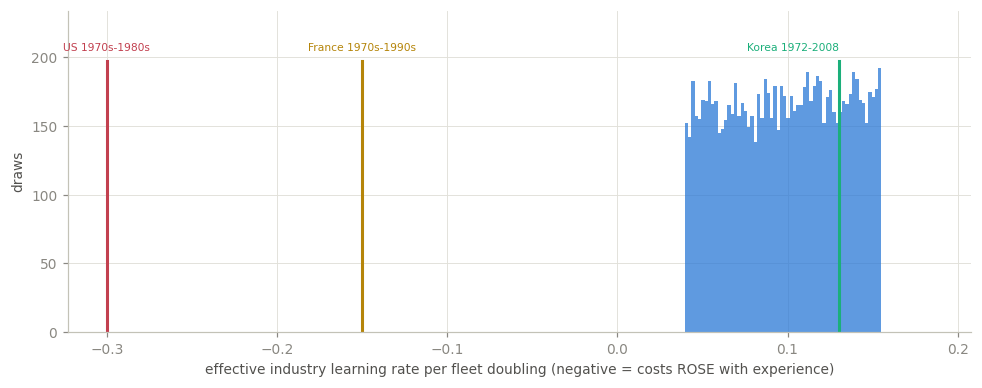

Figure note: hindcast - history vs the sampled learning-rate range (the model assumes a standardized-program regime).
wrote analysis\results\exports\01\hindcast_positions.csv


In [29]:
# QA5 - hindcast (report, not a pass/fail test; promoted to the paper body): run the model's
# effective industry learning rate against what history actually delivered. The engine presumes
# a standardized-program regime; the US/France cost-escalation record lies OUTSIDE its support
# by construction, and Korea's standardized program sits in its upper tail. Stating this is a
# domain-of-validity declaration: read every fan as conditional on a standardized program.
obs = {"Korea 1972-2008 (Lovering et al. 2016)":  +0.13,
       "France 1970s-1990s (Grubler 2010)":       -0.15,
       "US 1970s-1980s (Eash-Gates et al. 2020)": -0.30}
# Observed program rates are INDUSTRY-level per-doubling declines; the sampled LR is firm-level,
# so compare on the effective industry rate 1-(1-LR)(1-omega*LR)  (~1.3 x LR).
_w = WORLDS[SCHED_ORDER[0]]                      # LR marginals are identical across schedules (QA13)
lr_samp = 1 - (1 - _w["lr_large"])*(1 - OMEGA*_w["lr_large"])
print(f"sampled firm-level LR (large) implies an effective industry rate: "
      f"P5={lr_samp.quantile(.05):.1%}  P50={lr_samp.quantile(.50):.1%}  P95={lr_samp.quantile(.95):.1%}")
hind_rows = {}
for k, v in obs.items():
    pct = (lr_samp < v).mean()
    where = (f"P{100*pct:.0f} of the sampled range" if 0 < pct < 1
             else ("ABOVE the sampled support" if pct == 1 else "BELOW the sampled support"))
    hind_rows[k] = {"observed_rate": v, "position": where}
    print(f"  {k}: LR ~ {v:+.0%} -> {where}")
hindcast_tab = pd.DataFrame(hind_rows).T
hindcast_tab.to_csv(EXPORTS / "hindcast_positions.csv")

fig, ax = plt.subplots(figsize=(ps.W2, 3.6))
ax.hist(lr_samp, bins=60, color=ps.COL["large"], alpha=0.75)   # sampled LR is lr_large
ymax = ax.get_ylim()[1]
# Marker accents: green (inside support) -> gold -> red (outside support); gold, not
# the orange accent, to avoid reading France's marker as the SMR tech color.
for (k, v), col in zip(obs.items(), [ps.ACCENT["green"], ps.ACCENT["gold"], ps.ACCENT["red"]]):
    ax.plot([v, v], [0, ymax*0.98], color=col, lw=2)
    # Korea sits near the right edge: right-align its label at the marker so the
    # text grows leftward, clear of the canvas edge; labels sit above the bars.
    ax.text(v, ymax*1.01, k.split(" (")[0], rotation=0, va="bottom",
            ha="right" if k.startswith("Korea") else "center", fontsize=7, color=col)
# Widen the right x-margin so the sampled support's truncation edge sits visibly
# inside the axes, and add y-headroom so the labels clear the tallest bars.
_lo, _hi = ax.get_xlim()
ax.set_xlim(_lo, _hi + 0.06*(_hi - _lo))
ax.set_ylim(0, ymax*1.16)
ax.set_xlabel("effective industry learning rate per fleet doubling "
              "(negative = costs ROSE with experience)")
ax.set_ylabel("draws")
plt.tight_layout()
plt.show()                                     # display only (not a paper item)
print("Figure note: hindcast - history vs the sampled learning-rate range "
      "(the model assumes a standardized-program regime).")
print(f"wrote {paths.rel(EXPORTS / 'hindcast_positions.csv')}")

In [30]:
# QA6 - CES regression suite (five parts; occ_paths is the untouched sigma = 1 reference)
_sched = "2025 EO"
_world, _nus = WORLDS[_sched], USN_NEW["large"][_sched]

# (a) anchor invariance at every grid rho
for tech in TECH:
    for r in CES_RHO_GRID:
        assert np.allclose(occ_paths_ces(WORLDS[_sched], tech, USN_NEW[tech][_sched], ces_rho=r)
                           [:, yi(ANCHOR)],
                           WORLDS[_sched][f"boak_{tech}"].values), (tech, r)
# (b) rho -> 0 identity: reproduces the reference engine
for tech in TECH:
    assert np.allclose(occ_paths_ces(_world, tech, USN_NEW[tech][_sched], ces_rho=1e-10),
                       occ_paths(_world, tech, USN_NEW[tech][_sched]), rtol=1e-9, atol=1e-6), tech
# (c) autarky collapse: at s = 0 both channels grow proportionally, so the entire rho sweep
#     must be EXACTLY flat (degree-1 homogeneity), under both conventions; plus the tiny-base
#     closed form BOAK * ((1-LR)(1-omega LR))^log2(1 + N/2m)
wa = draw_world(400, "zero", rng_stream("qa6_autarky"))
wa[["s", "x_ls", "x_sl"]] = 0.0
for cval in (0, 1):
    wa["conv_full"] = cval
    base = occ_paths_ces(wa, "large", _nus, ces_rho=0.0)
    for r in CES_RHO_GRID:
        assert np.allclose(occ_paths_ces(wa, "large", _nus, ces_rho=r), base, rtol=1e-9), (cval, r)
wa["conv_full"] = 0
m = wa["n_vendors"].values[:, None].astype(float)
N = lag1(np.broadcast_to(_nus, (len(wa), T)))   # engine prices lagged stock
lr = wa["lr_large"].values[:, None]
tiny_analytic = wa["boak_large"].values[:, None] * ((1-lr)*(1-OMEGA*lr))**np.log2(1.0 + N/(2*m))
assert np.allclose(occ_paths_ces(wa, "large", _nus, ces_rho=0.0), tiny_analytic, rtol=1e-9)
# (d) continuity across the rho = 0 branch point
ces_seq = (-1e-3, -1e-6, 1e-10, 1e-6, 1e-3)
vals = [occ_paths_ces(_world, "large", _nus, ces_rho=r)[:, yi(2050)] for r in ces_seq]
assert all(np.isfinite(v).all() for v in vals)
maxstep = max(np.max(np.abs(a - b)/np.abs(b)) for a, b in zip(vals[:-1], vals[1:]))
assert maxstep < 1e-3, maxstep
print("QA6 (a-d) PASSED: CES anchor invariance, rho->0 identity, autarky collapse, "
      f"continuity at rho=0 (max relative step {maxstep:.2e})")
# (e) directional check - REPORTED, not asserted (monotonicity in rho is not a theorem in the
#     anchored form: E(t)/E(2030) is a ratio of two power means)
occ_grid = {r: occ_paths_ces(_world, "large", _nus, ces_rho=r)[:, yi(2050)] for r in CES_RHO_GRID}
G = np.column_stack([occ_grid[r] for r in CES_RHO_GRID])
d = np.diff(G, axis=1)
dec = (d < -1e-3).all(axis=1); inc = (d > 1e-3).all(axis=1)
flat = (np.abs(d) <= 1e-3).all(axis=1); nonmono = ~(dec | inc | flat)
print(f"QA6 (e) report - 2050 large OCC vs rho_CES ('{_sched}'): "
      + "  ".join(f"{r:+.0f}: ${np.median(occ_grid[r]):,.0f}" for r in CES_RHO_GRID))
print(f"  per-draw shape: {dec.mean():.1%} decreasing in rho, {inc.mean():.1%} increasing, "
      f"{flat.mean():.1%} ~flat, {nonmono.mean():.1%} non-monotone")

QA6 (a-d) PASSED: CES anchor invariance, rho->0 identity, autarky collapse, continuity at rho=0 (max relative step 2.03e-05)
QA6 (e) report - 2050 large OCC vs rho_CES ('2025 EO'): -1: $4,867  +0: $4,874  +1: $4,892
  per-draw shape: 50.0% decreasing in rho, 50.0% increasing, 0.0% ~flat, 0.0% non-monotone


In [31]:
# QA8 - duration-model anchors, mirroring the ReEDS engine's own self-test: at lambda = 0.5,
# zero noise, zero builds (series 2), the large next build is 79.0 months and the SMR base is
# floored at max(79 * ratio, 43) months.
wq = draw_world(8, "zero", rng_stream("qa8"))
wq["dur_lambda"] = 0.5
wq["dur_z"] = 0.0
d_large = duration_paths(wq, "large", ZEROS_T)
d_smr = duration_paths(wq, "smr", ZEROS_T)
assert np.allclose(d_large, 0.5*(INL_DUR_MOD[1] + INL_DUR_OPT[1])), d_large[0, 0]   # 79.0
assert np.allclose(d_smr, max(79.0*SMR_DUR_RATIO, SMR_DUR_FLOOR)), d_smr[0, 0]
print(f"QA8 PASSED: series-2 next build = {d_large[0,0]:.1f} months (large), "
      f"{d_smr[0,0]:.1f} months (SMR, ratio/floor applied) - matches the ReEDS engine convention")

QA8 PASSED: series-2 next build = 79.0 months (large), 53.0 months (SMR, ratio/floor applied) - matches the ReEDS engine convention


In [32]:
# QA13 - the six MCs must draw statistically identical worlds (only deployment differs).
# Two-sample Kolmogorov-Smirnov tests of every drawn marginal, each schedule vs the first.
if COMMON_RANDOM_NUMBERS:
    print("QA13 SKIPPED: common random numbers are ON, so the worlds are identical by construction")
else:
    ref = WORLDS[SCHED_ORDER[0]]
    cols = ["lr_large", "lr_smr", "boak_large", "boak_smr", "u", "s", "dur_lambda", "dur_z"]
    worst_p, worst_at = 1.0, None
    for sched in SCHED_ORDER[1:]:
        for c in cols:
            p = stats.ks_2samp(ref[c], WORLDS[sched][c]).pvalue
            if p < worst_p:
                worst_p, worst_at = p, (sched, c)
    # With 40 independent tests, small p-values occur by chance; only a catastrophic
    # distributional difference (p ~ 0) would indicate a coding error.
    assert worst_p > 1e-5, (worst_at, worst_p)
    print(f"QA13 PASSED: drawn marginals statistically identical across the six MCs "
          f"(worst KS p-value {worst_p:.3f} at {worst_at})")

QA13 PASSED: drawn marginals statistically identical across the six MCs (worst KS p-value 0.094 at ('COP28 tripling pledge', 'lr_large'))


## 13 · Engine constants and run record

`engine_constants.json` holds, at full precision, the constants that a later notebook needs to
re-derive durations and financing from `mc_perdraw.npz` without re-running this engine: the
duration dispersion σ, the INL curves, the SMR ratio and floor, the per-year interest base, the
spend profiles and the non-IDC financing multiplier. Notebook 10 reads it for the
construction-duration-floor table (Supplementary Table 6).

`mc_export_metadata.json` records the seed policy, the switches, the definitions of every exported
quantity and a SHA-256 fingerprint (first 16 hex digits) of every CSV and PNG this notebook wrote.
The npz is described by its array count, because its zip container carries write timestamps.

In [33]:
engine_constants = {
    "master_seed": MASTER_SEED, "n_draws_per_schedule": N_DRAWS,
    "years": YEARS.tolist(), "anchor_year": ANCHOR,
    "duration_dispersion_sigma": float(sig_hat),
    "inl_duration_moderate_months": INL_DUR_MOD.tolist(),
    "inl_duration_optimistic_months": INL_DUR_OPT.tolist(),
    "smr_duration_ratio": SMR_DUR_RATIO, "smr_duration_floor_months": SMR_DUR_FLOOR,
    "unit_gw": {t: TECH[t]["unit_gw"] for t in TECH},
    "interest_base": FIN["interest_base"].tolist(),
    "d_real": FIN["d_real"].tolist(),
    "spend_profile": {t: FIN["sched"][t].tolist() for t in TECH},
    "fin_mult_rest": {t: FIN_REST[t].tolist() for t in TECH},
    "note": ("fincapex = occ x ccmult(duration) x fin_mult_rest (2022 $/kW, no ITC); ccmult from "
             "interest_base and spend_profile re-stretched to round(duration/12) years (1-10); "
             "SMR duration = max(base x ratio, floor) x exp(dur_z x sigma)"),
}
with open(EXPORTS / "engine_constants.json", "w") as f:
    json.dump(engine_constants, f, indent=2)
print(f"wrote {paths.rel(EXPORTS / 'engine_constants.json')}")

wrote analysis\results\exports\01\engine_constants.json


In [34]:
import hashlib
import subprocess as _sp

def _sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()[:16]

try:
    GIT_HASH = _sp.run(["git", "rev-parse", "--short", "HEAD"], cwd=paths.REPO,
                       capture_output=True, text=True).stdout.strip() or "unavailable"
except Exception:
    GIT_HASH = "unavailable"

own_files = (sorted(EXPORTS.glob("*.csv")) + sorted(EXPORTS.glob("*.png"))
             + [FIGS_SI / "SF03_financed_capital_cost_all_trajectories.png"])
with np.load(EXPORTS / "mc_perdraw.npz") as _z:
    _n_arrays = len(_z.files)

metadata = {
    "generated_by": "z-ethan/notebooks/01_monte_carlo_cost_engine.ipynb",
    "port_source": "mc_cost_trajectories.ipynb of the development tree (engine code copied verbatim)",
    "fork_git_commit": GIT_HASH,
    "master_seed": MASTER_SEED,
    "seed_policy": "np.random.SeedSequence((MASTER_SEED, crc32(stream_name))) per named stream; "
                   "streams: world/{scen_token} per schedule (or world/common under CRN), "
                   "qa3/qa6_autarky/qa8 for test draws",
    "architecture": "one independent MC per schedule, N_DRAWS draws each; no schedule weights; "
                    "u independent over the full IAEA Low/High envelope, identical marginals in "
                    "all six MCs (verified QA13)",
    "n_draws_per_schedule": N_DRAWS,
    "schedules": {s: SCEN_TOKEN[s] for s in SCHED_ORDER},
    "switches": {"RANKING_FUNCTIONAL": RANKING_FUNCTIONAL,
                 "USE_ITC_IN_RANKING": USE_ITC_IN_RANKING,
                 "COMMON_RANDOM_NUMBERS": COMMON_RANDOM_NUMBERS,
                 "COPULA_SET": COPULA_SET,
                 "X_SPILL_MAX": X_SPILL_MAX},
    "occ_definition": "overnight capital cost, IDC-exclusive, $/kW in 2022 USD (ATB basis)",
    "duration_definition": "construction duration, first nuclear concrete -> commercial operation, "
                           "months (INL Fig. 18 'project duration' basis)",
    "fincapex_definition": "OCC x ReEDS cost_cap_fin_mult_noITC with ccmult at the draw's learned "
                           "duration (2_financials.gms replication); 2022 $/kW",
    "winner_rule": "argmin over techs of the ranking functional; loser channel = intl spillover + "
                   "drawn cross-tech x of the winner's program",
    "case_extraction": "none here; notebook 04 selects the ReEDS cases from mc_perdraw.npz",
    "duration_dispersion_sigma": round(float(sig_hat), 4),
    "smr_duration": {"ratio": round(SMR_DUR_RATIO, 4), "floor_months": SMR_DUR_FLOOR},
    "mc_perdraw_npz": {"arrays": _n_arrays},
    "files": {str(paths.rel(p)).replace("\\", "/"): _sha256(p) for p in own_files if Path(p).exists()},
}
with open(EXPORTS / "mc_export_metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)
print(f"wrote {paths.rel(EXPORTS / 'mc_export_metadata.json')}: fork commit {GIT_HASH}, "
      f"{len(metadata['files'])} files fingerprinted, npz with {_n_arrays} arrays")

wrote analysis\results\exports\01\mc_export_metadata.json: fork commit d7005f4, 12 files fingerprinted, npz with 108 arrays
